# Stochastic Processes: Rates, Waiting, and Dependence

*Mathematical Rules of Thumb · Jason Karpeles · Chapter 14*

Rates, Waiting, and Dependence

Open [the interactive reader](reader.html) to explore the supported parameter choices without running code. Saved figures and calculations below can be read as they are. All example inputs are constructed.

Optional reproduction requires Python, NumPy, Matplotlib and IPython. All mathematical functions and inputs are included here.

In [1]:
import io
import matplotlib
matplotlib.use('Agg')
from IPython.display import Image, Markdown, display
from cycler import cycler
"""Constructed teaching calculations shared by readers and portable notebooks.

Requires NumPy and Matplotlib. No measurements, online data or trained models.
All stochastic illustrations use stated, fixed seeds.
"""
import math
import itertools
from collections import deque
import numpy as np
import matplotlib.pyplot as plt


def canvas(xlabel, ylabel, title, two=False):
    fig, axes = plt.subplots(1, 2 if two else 1, figsize=(10, 4.4), layout='constrained')
    for ax in np.atleast_1d(axes):
        ax.grid(alpha=.18)
        ax.set(xlabel=xlabel, ylabel=ylabel)
    np.atleast_1d(axes)[0].set_title(title)
    return fig, axes


def integer_ticks(ax, axis='x'):
    from matplotlib.ticker import MaxNLocator
    (ax.xaxis if axis=='x' else ax.yaxis).set_major_locator(MaxNLocator(integer=True))


def bits(x):
    return f'{x:.6g} bit'+('' if x==1 else 's')


def result(fig, ax, metrics, text):
    for a in np.atleast_1d(ax):
        if a.get_legend_handles_labels()[0]:
            old=a.get_legend()
            a.legend(fontsize=9,loc=old._loc if old is not None else 'best')
    return fig, metrics, text


def illustrate(chapter, demo, p):
    """Return an executed figure, metrics and interpretation for one example."""
    fig,metrics,text=globals()[f'chapter_{chapter:02d}'](demo, p)
    # Mark a selected point on comparisons whose full curve stays fixed.
    if (chapter,demo) in {(9,1),(11,1),(11,3),(13,2),(15,1),(15,2),(15,3),
                           (16,1),(17,2),(17,3),(18,3),(19,3),(20,3),(22,2),(23,3)}:
        ax=fig.axes[0];ax.axvline(p,color='#a26913',linestyle=':',label='Selected input')
        ax.legend(fontsize=9)
    return fig,metrics,text


def chapter_01(d, p):
    if d == 1:
        x=np.linspace(0,.2,201); exact=(1+x)**5; linear=1+5*x
        fig,ax=canvas('Fractional input increase', 'Response multiplier', 'Where linearization bends')
        ax.plot(x,exact,label='Exact fifth power');ax.plot(x,linear,'--',label='Linear estimate');ax.axvline(p,color='#a26913',linestyle=':',label='Selected input')
        a=(1+p)**5;b=1+5*p;m={'Exact multiplier':a,'Linear estimate':b,'Absolute error':abs(a-b)}
        t=f'An input increase of {100*p:g}% gives {a:.6g}, versus {b:.6g} from linearization. Judge the {abs(a-b):.6g} error against your tolerance.'
    elif d == 2:
        k=np.arange(1,21);tails=p**k/(1-p)
        fig,ax=canvas('First omitted exponent k','Infinite tail','Tail = first omitted term × 1/(1−r)')
        ax.semilogy(k,tails,label='Exact tail');ax.semilogy(k,p**k,'--',label='First omitted term');ax.scatter([5],[p**5/(1-p)],color='#a26913',zorder=3,label='Tail after exponent 4 (k=5)');integer_ticks(ax)
        m={'Ratio r':p,'Tail from r^5 onward':p**5/(1-p),'Tail / first term':1/(1-p)}
        t=f'The tail starting at r^5 equals r^5/(1-r). At r={p:g}, its multiplier over the first omitted term is {1/(1-p):.6g}; a ratio near one makes the tail much larger.'
    elif d==3:
        x=np.linspace(-3,3,301);y=x*x+p*x+1
        fig,ax=canvas('x','x² + b x + 1','Roots change at the discriminant boundary')
        ax.plot(x,y,label=f'b={p:g}');ax.axhline(0,color='gray');disc=p*p-4
        m={'Discriminant':disc,'Real root count':2 if disc>0 else 1 if disc==0 else 0,'Vertex x':-p/2}
        t=f'The discriminant b²-4 is {disc:g}. This gives '+('two distinct real roots.' if disc>0 else 'one repeated real root.' if disc==0 else 'no real roots; the two roots are complex conjugates.')
    elif d==4:
        r=np.linspace(.005,.25,250);fig,ax=canvas('Growth rate per period (%)','Rule-of-70 error (% of exact time)','How far the rule of 70 drifts as the rate grows')
        ax.plot(100*r,100*(.7/r-np.log(2)/np.log1p(r))/(np.log(2)/np.log1p(r)),label='(70/rate% − exact) / exact');ax.axhline(0,color='gray');ax.axvline(100*p,color='#a26913',linestyle=':',label='Selected rate')
        ex=math.log(2)/math.log1p(p);est=70/(100*p);m={'Rate per period (%)':100*p,'Exact doubling time (periods)':ex,'Rule-of-70 estimate (periods)':est,'Estimate error (periods)':est-ex}
        t=f'At {100*p:g}% per period the exact doubling time is {ex:.4g} periods; the rule of 70 says {est:.4g}. '+('Good enough for mental arithmetic.' if abs(est-ex)/ex<.03 else f'The shortcut is {100*abs(est-ex)/ex:.2g}% too short at this high rate, because 70 matches continuous growth and ln(1+r) falls below r as r grows.')
    elif d==5:
        x=np.linspace(-4,8,1201);x=x[np.abs(x-3)>.05];y=(x+1)/(x-3)
        fig,ax=canvas('x','(x+1)/(x-3)','Multiplying by x−3 flips the inequality when x<3')
        ax.plot(x[x<3],y[x<3],color='#136f75',label='(x+1)/(x-3)');ax.plot(x[x>3],y[x>3],color='#136f75');ax.axhline(0,color='gray');ax.axvline(3,color='gray',linestyle='dashed',label='Excluded x=3')
        ax.axvspan(-1,3,color='#136f75',alpha=.12,label='True solution [-1, 3)');ax.plot([-4,-1],[-9.5,-9.5],lw=5,color='#a26913',label='Naive answer x ≤ -1');ax.set(ylim=(-10,10))
        v=(p+1)/(p-3);true=v<=0;naive=p+1<=0;ax.scatter([p],[v],color='black',zorder=3,label=f'Test x={p:g}')
        m={'Test x':p,'(x+1)/(x-3)':v,'Truly satisfies':'yes' if true else 'no','Naive x ≤ -1 says':'yes' if naive else 'no'}
        t=f'At x={p:g} the fraction equals {v:.4g}, so the inequality is '+('true' if true else 'false')+'. Cross-multiplying without a sign check gives x+1 ≤ 0, which says '+('true' if naive else 'false')+'. '+('The two agree here only because x>3 keeps the denominator positive.' if true==naive else 'They disagree because x<3 makes the denominator negative, which reverses the inequality.')
    return result(fig,ax,m,t)


def chapter_02(d,p):
    if d==1:
        x=np.linspace(.5,3,151);fig,ax=canvas('Linear scale factor','Relative size','Similar shapes scale by different powers')
        ax.plot(x,x**2,label='Area');ax.plot(x,x**3,label='Volume');ax.axvline(p,color='#a26913',linestyle=':',label='Selected input')
        m={'Area factor':p*p,'Volume factor':p**3,'Boundary / area factor':1/p};t=f'A similar shape scaled by {p:g} has area multiplied by {p*p:g}, volume by {p**3:g}, and boundary-to-area ratio by {1/p:.6g}. These multipliers hold only when every length scales by the same factor.'
    elif d==2:
        radius=10.;x=np.linspace(0,12,151);exact=radius-np.sqrt(radius**2-(x/2)**2);estimate=x*x/(8*radius)
        fig,ax=canvas('Chord length','Sagitta (same length units)','Shallow arcs and their approximation');ax.plot(x,exact,label='Exact');ax.plot(x,estimate,'--',label='c²/(8R)');ax.axvline(p,color='#a26913',linestyle=':',label='Selected input')
        a=radius-math.sqrt(radius**2-(p/2)**2);b=p*p/(8*radius);m={'Radius':radius,'Exact sagitta':a,'Approximate sagitta':b,'Relative error (vs exact sagitta)':abs(a-b)/a};t=f'With radius 10 and chord {p:g}, sagitta is {a:.6g}. The shallow-arc estimate is {b:.6g}; its relative error grows as the chord becomes less shallow.'
    elif d==3:
        n=np.arange(3,81);ratio=n*np.sin(2*np.pi/n)/(2*np.pi)
        fig,ax=canvas('Polygon side count','Fractional missing area','Inscribed polygons approach a circle');ax.loglog(n,1-ratio,label='Exact missing fraction');ax.loglog(n,2*np.pi**2/(3*n*n),'--',label='Leading n⁻² scale');ax.axvline(p,color='#a26913',linestyle=':',label='Selected input');ax.set_xticks([3,5,10,20,40,80]);ax.set_xticklabels(['3','5','10','20','40','80']);ax.minorticks_off()
        err=1-p*math.sin(2*math.pi/p)/(2*math.pi);m={'Sides':p,'Circle area fraction missing':err};t=f'The regular {p:g}-gon misses {100*err:.6g}% of its unit-circle area. The n⁻² curve is an asymptotic comparison, not an exact formula for small polygons.'
    elif d==4:
        a,b=3.,4.;fig,ax=canvas('x (length units)','y (length units)','Can sides 3, 4 and c close into a triangle?')
        lo,hi=b-a,a+b;ok=lo<p<hi
        th=np.linspace(0,2*np.pi,300);ax.plot([0,b],[0,0],lw=3,color='#333333',label='Side 4 (fixed base)');ax.plot(p*np.cos(th),p*np.sin(th),':',color='#a26913',label=f'Reach of side c={p:g} from left end');ax.plot(b+a*np.cos(th),a*np.sin(th),':',color='#136f75',label='Reach of side 3 from right end')
        if ok:
            X=(b*b+p*p-a*a)/(2*b);Y=math.sqrt(p*p-X*X);ax.plot([0,X],[0,Y],lw=3,color='#a26913');ax.plot([X,b],[Y,0],lw=3,color='#136f75');ax.scatter([X],[Y],color='black',zorder=3,label='Apex where the reaches meet')
        ax.set(xlim=(-9,9),ylim=(-8.5,8.5));ax.set_aspect('equal');ax.legend(fontsize=9,loc='lower left')
        m={'Side c':p,'Allowed range for c':f'{lo:g} < c < {hi:g}','Triangle exists':'yes' if ok else 'no'}
        t=f'With c={p:g}, '+(f'every side is shorter than the other two combined, so a real triangle forms. Only now is triangle algebra (angles, area) safe.' if ok else f'c is {"shorter than 4 minus 3" if p<=lo else "longer than 3 plus 4"}, so the ends cannot meet. Any area or angle formula would return nonsense or an error.')
    return result(fig,ax,m,t)


def chapter_03(d,p):
    if d==1:
        x=np.linspace(0,.8,201);fig,ax=canvas('Angle (radians)','Absolute error','Small-angle sine has a cubic error bound');ax.plot(x,x-np.sin(x),label='Actual error');ax.plot(x,x**3/6,'--',label='Cubic bound');a=math.radians(p);ax.axvline(a,color='#a26913',linestyle=':',label='Selected input')
        m={'Angle in radians':a,'Sine':math.sin(a),'Approximation':a,'Error bound':a**3/6};t=f'{p:g}° is {a:.6g} radians. Substitute radians into the approximation; the error is bounded by {a**3/6:.6g}.'
    elif d==2:
        a=math.radians(p);fig,ax=canvas('x component','y component','atan2 retains the quadrant');ax.quiver(0,0,math.cos(a),math.sin(a),angles='xy',scale_units='xy',scale=1,color='#136f75',label='Selected vector');ax.quiver(0,0,-math.cos(a),-math.sin(a),angles='xy',scale_units='xy',scale=1,color='#9aa3a8',label='Opposite vector (same ratio y/x)');correct=math.degrees(math.atan2(math.sin(a),math.cos(a)));wrong=math.degrees(math.atan(math.sin(a)/math.cos(a)));w=math.radians(wrong);ax.plot([0,1.1*math.cos(w)],[0,1.1*math.sin(w)],':',color='#a26913',label='Direction plain atan reports');ax.set(xlim=(-1.2,1.2),ylim=(-1.2,1.2));ax.set_aspect('equal')
        m={'atan2 direction (degrees)':correct,'Plain atan ratio (degrees)':wrong};same=abs(correct-wrong)<1e-9;wrap=f' ({p:g}° and {correct:.6g}° name the same direction.)' if abs(correct-p)>1e-9 else ''
        t=f'The vector and its opposite share the component ratio y/x. Here atan2 gives {correct:.6g}°.{wrap} '+('Plain atan also gives '+f'{wrong:.6g}°, because x>0 places this vector in the half-plane plain atan covers.' if same else f'Plain atan gives {wrong:.6g}°, which points along the opposite vector.')
    elif d==3:
        x=np.logspace(-12,-1,120);direct=1-np.cos(x);stable=2*np.sin(x/2)**2
        fig,ax=canvas('Angle (radians)','Relative difference from stable identity','Subtraction can erase a small quantity');ax.loglog(x,np.maximum(abs(direct-stable)/stable,1e-18),label='Direct subtraction error');ax.axvline(p,color='#a26913');a=1-math.cos(p);b=2*math.sin(p/2)**2
        rel=abs(a-b)/b;m={'Direct 1 − cos(x)':a,'Half-angle identity':b,'Relative difference':rel};t=f'At x={p:g}, direct subtraction gives {a:.10g}, while the equivalent half-angle expression gives {b:.10g}. '+('Binary64 rounding made cos(x) exactly 1, so the direct result was erased.' if a==0 else f'The direct result survives but has lost digits: its relative difference is {rel:.2g}.')
    elif d==4:
        A=math.radians(30);b=10.;h=b*math.sin(A);fig,ax=canvas('x (length units)','y (length units)','Side a swings from C; how many places meet the base?')
        C=(b*math.cos(A),h);ax.plot([0,22],[0,0],color='gray',label='Base line from A');ax.plot([0,C[0]],[0,C[1]],lw=3,label='Side b=10');th=np.linspace(0,2*np.pi,300);ax.plot(C[0]+p*np.cos(th),C[1]+p*np.sin(th),':',color='#a26913',label=f'Reach of side a={p:g}')
        xs=[] if p<h else sorted({C[0]+s*math.sqrt(p*p-h*h) for s in(-1,1)});xs=[x for x in xs if x>1e-9]
        for x in xs: ax.plot([C[0],x],[C[1],0],lw=2,color='#136f75')
        ax.scatter(xs,[0]*len(xs),color='#136f75',zorder=3,label='Valid vertex B' if xs else None);ax.set(xlim=(-3,22),ylim=(-8,14));ax.set_aspect('equal')
        m={'Height b·sin A':h,'Side a':p,'Number of triangles':len(xs)}
        t={0:f'a={p:g} is shorter than the height {h:g}, so side a cannot reach the base: no triangle. Arcsin would fail with sin B>1.',2:f'a={p:g} is between the height {h:g} and b=10, so it meets the base twice: two valid triangles. Arcsin returns only the acute B; the obtuse angle 180° minus B is also valid.',1:f'a={p:g} is at least b=10, so only one meeting point lies on the correct side of A: one triangle.'}[len(xs)]
    return result(fig,ax,m,t)


def chapter_04(d,p):
    if d==1:
        x=np.linspace(80,120,201);fig,ax=canvas('x','Square root','Tangent estimates need an error budget');ax.plot(x,np.sqrt(x),label='Exact');ax.plot(x,10+(x-100)/20,'--',label='Tangent at 100');ax.axvline(100+p,color='#a26913',linestyle=':',label='Selected input');a=math.sqrt(100+p);b=10+p/20;bound=p*p/(8*min(100,100+p)**1.5)
        m={'Exact':a,'Linear estimate':b,'Actual error':abs(a-b),'Remainder bound':bound};t=f'For x=100+{p:g}, the linear estimate differs by {abs(a-b):.6g}. Bounding the second derivative on the intervening interval certifies error at most {bound:.6g}.'
    elif d==2:
        step=(p+2/p)/2;x=np.linspace(.1,max(3,step+.5),301);fig,ax=canvas('x','x² − 2','Newton follows a tangent');ax.plot(x,x*x-2,label='Function');ax.plot(x,p*p-2+2*p*(x-p),'--',label='Tangent');ax.axhline(0,color='gray');ax.scatter([p,step],[p*p-2,0],color='#a26913',zorder=3,label='Start and next x')
        m={'Starting x':p,'Next x':step,'Next residual':step*step-2};t=f'The tangent from x={p:g} crosses zero at {step:.6g}. '+(f'The step overshot: the residual grew from {abs(p*p-2):.6g} to {abs(step*step-2):.6g}. Newton is reliable only near the root, so bracket first.' if abs(step*step-2)>abs(p*p-2) else f'The residual shrank from {abs(p*p-2):.6g} to {abs(step*step-2):.6g}, so this step helped.')
    elif d==3:
        x=np.arange(1,101);a=x.astype(float)**(-p);partial=np.cumsum(a);fig,ax=canvas('Terms retained','Partial sum','A p-series threshold is about the infinite tail');ax.plot(x,partial,label=f'p={p:g}');tail=100**(1-p)/(p-1) if p>1 else 'No finite tail bound'
        m={'Exponent p':p,'100-term sum':partial[-1],'Integral upper bound on tail':tail};t='Adding n⁻ᵖ forever gives a finite total only when p>1. '+(f'At p={p:g}, the tail after 100 is at most {tail:.6g}.' if p>1 else 'A finite partial sum does not establish convergence; this selected series diverges.')
    elif d==4:
        x=1.;k=np.arange(0,11);part=np.cumsum([x**j/math.factorial(j) for j in k]);err=abs(math.e-part);nxt=np.array([x**(j+1)/math.factorial(j+1) for j in k])
        fig,ax=canvas('Polynomial degree n','Error at x=1','Taylor error for eˣ tracks the first omitted term');ax.semilogy(k,err,'o-',label=r'Actual error $|e-T_n(1)|$');ax.semilogy(k,nxt,'s',linestyle='dashed',label='First omitted term 1/(n+1)!');ax.axvline(p,color='#a26913',linestyle=':',label='Selected degree');integer_ticks(ax)
        e=err[p];s=nxt[p];m={'Degree n':p,'Actual error':e,'First omitted term':s,'Actual / omitted':e/s}
        t=f'Stopping at degree {p} leaves error {e:.3g}. The first omitted term {s:.3g} predicts it within a factor {e/s:.3g}, so you can read the error budget before computing e. '+('At this low degree the later terms still add a noticeable share.' if e/s>1.2 else 'Higher degrees make the first omitted term almost the whole story.')
    elif d==5:
        x=np.linspace(-.5,.5,1001);x=x[np.abs(x)>.004];y=(np.sin(x)+p)/x
        fig,ax=canvas('x','(sin x + a) / x','L\'Hôpital needs 0/0 first');ax.plot(x[x<0],y[x<0],color='#136f75',label=f'a={p:g}');ax.plot(x[x>0],y[x>0],color='#136f75');ax.axhline(1,color='#a26913',linestyle='dashed',label='Blind L\'Hôpital: cos 0 / 1 = 1');ax.set(ylim=(-6,6))
        r=(math.sin(.01)+p)/.01;m={'Numerator at x=0':p,'Form at x=0':'0/0' if p==0 else 'nonzero/0','Ratio at x=0.01':r,'Blind L\'Hôpital answer':1}
        t=(f'With a=0 the form is 0/0, so L\'Hôpital applies and the limit really is 1; the ratio at x=0.01 is {r:.6g}.' if p==0 else f'With a={p:g} the numerator tends to {p:g} while the denominator tends to 0, so the ratio blows up (it is {r:.4g} at x=0.01) and has no finite limit. Differentiating anyway still returns 1, a wrong answer.')
    return result(fig,ax,m,t)


def chapter_05(d,p):
    if d==1:
        n=np.arange(max(21,math.ceil(math.log(.01)/math.log(p))+4));x=1-p**n;error=p**n;certificate=p**n/(1-p)*(1-p)
        fig,ax=canvas('Iteration','Absolute error','A contraction supplies a certificate');ax.semilogy(n,error,lw=4,alpha=.45,label='Exact error to fixed point 1');ax.semilogy(n,certificate,'--',label='Contraction bound (coincides here)');ax.axhline(.01,color='gray',linestyle=':',label='Target .01');ax.axvline(math.ceil(math.log(.01)/math.log(p)),color='#a26913',label='Steps needed');m={'Contraction q':p,'Error after 10 steps':p**10,'Steps for error ≤ .01':math.ceil(math.log(.01)/math.log(p))};t=f'T(x)=q x+(1-q), starting at zero, has error qⁿ. At q={p:g}, {m["Steps for error ≤ .01"]} steps suffice for .01 error. In this affine example the bound equals the exact error, so the two curves coincide. q must be strictly below one.'
    elif d==2:
        x=np.linspace(0,1,501);fig,ax=canvas('x in [0,1]','xⁿ','Pointwise convergence is not uniform');ax.plot(x,x**p,label=f'n={p:g}');ax.scatter([1],[1],label='Endpoint remains 1');m={'Value at x=.9':.9**p,'Value at x=1':1,'Supremum error to pointwise limit':1};t=f'Increasing n suppresses xⁿ at every fixed x<1, but a boundary layer remains near one. The supremum difference from the discontinuous pointwise limit is 1 for every n; this is not uniform convergence.'
    elif d==3:
        n=np.arange(1,31);tail=p**(n+1)/(1-p);fig,ax=canvas('Last retained exponent n','Uniform remainder ceiling','A geometric majorant controls every x');ax.semilogy(n,tail,label='Geometric bound on the tail');ax.yaxis.set_major_formatter(__import__('matplotlib').ticker.LogFormatterSciNotation(labelOnlyBase=False));m={'Uniform |x| ceiling q':p,'Remainder after exponent 10':p**11/(1-p)};t=f'For |x|≤{p:g}<1, the series sum xⁿ is uniformly controlled by sum qⁿ. Its tail after exponent 10 is at most {m["Remainder after exponent 10"]:.6g}; the bound deteriorates as q approaches one.'
    elif d==4:
        pos=iter(1/np.arange(1,10**6,2));neg=iter(-1/np.arange(2,10**6,2));s=0.;path=[]
        for _ in range(3000): s+=next(pos) if s<=p else next(neg);path.append(s)
        fig,ax=canvas('Terms used','Running sum','Same terms ±1/n, new order, new sum');ax.semilogx(range(1,3001),path,label='Rearranged sum');ax.axhline(math.log(2),color='gray',linestyle='dashed',label='Usual order: ln 2 ≈ 0.693');ax.axhline(p,color='#a26913',linestyle=':',label=f'Target {p:g}')
        m={'Target':p,'Sum after 3000 terms':path[-1],'Usual-order sum ln 2':math.log(2)}
        t=f'Adding positives while at or below {p:g} and negatives while above steers the running sum to {path[-1]:.4g}. '+'The terms are exactly those of the ln 2 series; only the order changed. Because the sum of |terms| diverges, order is part of the answer.'
    return result(fig,ax,m,t)


def chapter_06(d,p):
    if d==1:
        theta=np.linspace(0,2*np.pi,361);z=np.exp(1j*theta);fig,ax=canvas('Real part','Imaginary part','A power multiplies the argument');ax.plot(z.real,z.imag,'--',color='#9aa3a8',label='Unit circle');ang=np.linspace(0,np.radians(135*p),400);rad=.25+.12*ang/(2*np.pi);ax.plot(rad*np.cos(ang),rad*np.sin(ang),color='#a26913',label='Unwrapped angle path');point=np.exp(1j*np.radians(135));out=point**p;ax.quiver(0,0,point.real,point.imag,angles='xy',scale_units='xy',scale=1,color='#9aa3a8',label='Input z (135°)');ax.quiver(0,0,out.real,out.imag,angles='xy',scale_units='xy',scale=1,color='#136f75',label=f'Output z^{p:g}');ax.set(xlim=(-1.3,1.3),ylim=(-1.3,1.3));ax.set_aspect('equal');unwrapped=135*p;principal=math.degrees(np.angle(out));turns=round((unwrapped-principal)/360);m={'Input argument (degrees)':135,'Unwrapped output argument':unwrapped,'Principal output argument':principal,'Full turns lost by principal value':turns};t=f'Integer power {p:g} multiplies the argument: 135°×{p:g}={unwrapped:g}°. '+(f'The principal argument wraps this to {principal:.6g}°, dropping {turns} full turn{"s" if turns!=1 else ""}; only the unwrapped angle records them.' if turns else f'Here {unwrapped:g}° already lies in (−180°,180°], so no wrap occurs.')
    elif d==2:
        k=np.arange(0,7);fig,ax=canvas('Derivative order k','Cauchy upper bound','A larger analytic disk gives stronger bounds')
        for R in (1,2,4):
            b=np.array([math.factorial(int(n))*3/R**n for n in k]);ax.semilogy(k,b,'o-',lw=2.5 if R==p else 1,alpha=1 if R==p else .35,label=f'k! M / Rᵏ, R={R}'+(' (selected)' if R==p else ''))
        integer_ticks(ax);m={'Disk radius R':p,'Boundary bound M':3,'Second derivative ceiling':6/p**2};t=f'If the function is analytic on and inside this disk and its boundary modulus is at most 3, |f″(0)|≤6/R²={6/p**2:.6g}. Doubling the radius cuts this ceiling by four. A function that stays tame across a wide disk cannot bend sharply at its center.'
    elif d==3:
        theta=np.linspace(0,2*np.pi,501);z=np.exp(1j*theta);w=z**3+p;fig,ax=canvas('Real part','Imaginary part','Boundary image and roots of z³ + a');ax.plot(w.real,w.imag,label='Mapped unit-circle boundary');ax.scatter([0],[0],color='#a26913',label='Origin');roots=np.roots([1,0,0,p]);ax.plot(np.cos(theta),np.sin(theta),':',color='#9aa3a8',label='Unit circle |z|=1');ax.scatter(roots.real,roots.imag,marker='x',s=70,color='#aa4e37',zorder=3,label='Roots of z³+a');ax.set(xlim=(-1.4,2.4),ylim=(-1.3,2.3));ax.set_aspect('equal');count=int(np.sum(abs(roots)<1-1e-10));m={'Constant a':p,'Strict domination |a| < 1':p<1,'Zeros strictly inside disk':count};t=f'For a={p:g}, '+('Rouché compares z³ with a on |z|=1 and gives three interior zeros.' if p<1 else 'strict boundary domination fails. At a=1 the zeros lie on the boundary; above one they lie outside. The failed theorem test must not be treated as a zero-count proof.')
    elif d==4:
        theta=np.linspace(0,2*np.pi,4001)[:-1];poles=np.array([.5,1.5]);res=np.array([-1.,1.]);z=p*np.exp(1j*theta);I=np.sum(1/((z-.5)*(z-1.5))*1j*z)*(2*np.pi/len(theta));inside=abs(poles)<p;pred=2j*np.pi*res[inside].sum();fig,ax=canvas('Real part','Imaginary part','Only poles inside the contour count');ax.plot(p*np.cos(theta),p*np.sin(theta),color='#136f75',lw=2,label=f'Contour |z|={p:g}');inside.any() and ax.scatter(poles[inside],[0]*inside.sum(),marker='x',s=90,color='#aa4e37',zorder=3,label='Enclosed pole');(~inside).any() and ax.scatter(poles[~inside],[0]*(~inside).sum(),marker='x',s=90,color='#9aa3a8',zorder=3,label='Pole outside');[ax.annotate(f'residue {r:+g}',(q,.2 if r<0 else -.3),ha='center') for q,r in zip(poles,res)];ax.set(xlim=(-2.3,4.6),ylim=(-2.3,2.3));ax.set_aspect('equal');m={'Contour radius':p,'Poles enclosed':int(inside.sum()),'Sum of enclosed residues':res[inside].sum(),'Predicted integral 2πi×sum':f'{pred.imag:.6g}i','Numerical integral':f'{round(I.real,9)+0:.6g}{round(I.imag,9)+0:+.6g}i'};t=f'f(z)=1/((z−0.5)(z−1.5)) has residue −1 at 0.5 and +1 at 1.5. '+({0:'The contour encloses neither pole, so the integral is 0. The function is analytic inside, and nothing contributes.',1:f'Only the pole at 0.5 is inside, so the integral is 2πi×(−1)≈{pred.imag:.6g}i. The pole outside has no effect.',2:'Both poles are inside. Their residues cancel, so the integral is 0 again, even though the function blows up twice inside the contour.'}[int(inside.sum())])
    return result(fig,ax,m,t)


def chapter_07(d,p):
    if d==1:
        # The perturbation is aligned with the weak singular direction.
        A=np.diag([1.,1/p]);b=np.array([1.,0.]);delta=np.array([0.,1e-8]);x=np.linalg.solve(A,b);xp=np.linalg.solve(A,b+delta)
        fig,ax=canvas('Condition number κ','Relative forward error','A tiny right-hand-side change can be amplified');k=np.logspace(0,8,100);ax.loglog(k,1e-8*k,label='Weak-direction perturbation');ax.scatter([p],[np.linalg.norm(xp-x)/np.linalg.norm(x)]);m={'Condition number':np.linalg.cond(A),'Relative input perturbation':1e-8,'Relative solution change':np.linalg.norm(xp-x)/np.linalg.norm(x),'Perturbed solve residual':np.linalg.norm(A@xp-(b+delta))};t=f'A=diag(1,1/κ), b=(1,0), δb=(0,10⁻⁸). The actual solve amplifies this chosen perturbation by κ={p:g}; its small residual does not undo sensitivity to input changes.'
    elif d==2:
        x=np.linspace(0,1,101);A=np.column_stack([np.ones_like(x),x]);b=2+3*x+.1*np.sin(9*x);coef=np.linalg.lstsq(A,b,rcond=None)[0];res=b-A@coef;fig,ax=canvas('x','Observed / fitted value','Least squares fits a constructed dataset',two=True);ax[0].plot(x,b,'.',label='Constructed observations');ax[0].plot(x,A@coef,label='Fit with intercept');wrong=np.linalg.lstsq(A[:,1:],b,rcond=None)[0];ax[0].plot(x,A[:,1:]@wrong,'--',label='Intercept omitted');chosen=res if p=='include' else b-A[:,1:]@wrong;ax[1].plot(x,chosen,label='Selected residual');ax[1].set(ylabel='Residual',title=f'Intercept: {p}')
        m={'Fitted intercept':coef[0] if p=='include' else 0,'Fitted slope':coef[1] if p=='include' else wrong[0],'Residual RMS':np.sqrt(np.mean(chosen**2))};t='The data are 2+3x+.1 sin(9x), not measurements. '+('With an intercept the line recovers 2+3x, and the leftover wiggle of RMS size about .07 is the sin term no straight line can capture.' if p=='include' else 'Forcing the line through the origin doubles the slope to about 6 and leaves residuals near 1 that slope steadily. A better solver cannot fix this: the model itself is wrong.')
    elif d==3:
        A=np.diag([10.,3.,1.,.1]);u,s,v=np.linalg.svd(A);low=(u[:,:p]*s[:p])@v[:p];err=np.linalg.norm(A-low,2);fig,ax=canvas('Singular value index','Magnitude','Truncation error is priced by the next singular value');ax.semilogy(np.arange(1,5),s,'o-',label='Singular values');ax.axvline(p+.5,color='#a26913',label=f'Truncation after rank {p}');integer_ticks(ax);m={'Retained rank':p,'Actual spectral error':err,'Next singular value':s[p] if p<4 else 0};t=f'Keeping rank {p:g} gives spectral error {err:.6g}, equal to the next singular value in this actual SVD reconstruction. Compression is justified by an error budget, not rank alone.'
    elif d==4:
        lam=np.array([1.,p,.3]);x=np.ones(3)/np.sqrt(3);err=[]
        for k in range(60):x=lam*x;x/=np.linalg.norm(x);err.append(np.linalg.norm(x-np.sign(x[0])*np.array([1,0,0])))
        err=np.array(err);hit=int(np.argmax(err<1e-6))+1 if (err<1e-6).any() else None;fig,ax=canvas('Iteration','Distance from top eigenvector','Power iteration slows as the eigenvalue ratio nears one');k=np.arange(1,61);ax.semilogy(k,err,'o-',ms=3,color='#136f75',label=f'Actual error, ratio {p:g}');ax.semilogy(k,err[0]*p**(k-1),ls='dashed',color='#a26913',label=f'Predicted shrink: ×{p:g} per step');ax.axhline(1e-6,color='#9aa3a8',ls=':',label='Target 10⁻⁶');ax.set_ylim(1e-17,2);integer_ticks(ax);m={'Eigenvalue ratio |λ₂/λ₁|':p,'Error after 60 steps':err[-1] if err[-1]>1e-16 else 'Below 1e-16 (rounding level)','Steps to reach 10⁻⁶':hit if hit else 'More than 60'};t=f'Matrix diag(1,{p:g},0.3), start (1,1,1)/√3. Each step multiplies the error by about {p:g}. '+(f'The error passes 10⁻⁶ in {hit} steps.' if hit else f'After 60 steps the error is still {err[-1]:.3g}. A ratio this close to one needs about {math.ceil(math.log(1e-6)/math.log(p))} steps, so use a shift or a different method.')
    elif d==5:
        rng=np.random.default_rng(705);U,_=np.linalg.qr(rng.standard_normal((50,2)));V,_=np.linalg.qr(rng.standard_normal((2,2)));A=U@np.diag([1.,1/p])@V.T;xt=np.array([1.,1.]);b=A@xt;Q,R=np.linalg.qr(A);xq=np.linalg.solve(R,Q.T@b);xn=np.linalg.solve(A.T@A,A.T@b);eq=np.linalg.norm(xq-xt)/np.linalg.norm(xt);en=np.linalg.norm(xn-xt)/np.linalg.norm(xt)
        ks=np.logspace(0,8,60);fig,ax=canvas('Condition number κ of A','Relative error in the solution','Normal equations square the condition number');ax.loglog(ks,np.maximum(ks*2.2e-16,1e-17),color='#136f75',label='QR scale: κ × 2.2×10⁻¹⁶');ax.loglog(ks,np.minimum(ks**2*2.2e-16,10),ls='dashed',color='#a26913',label='Normal equations scale: κ² × 2.2×10⁻¹⁶');ax.scatter([p],[max(eq,1e-17)],s=90,color='#136f75',zorder=3,label='Actual QR error');ax.scatter([p],[max(en,1e-17)],s=90,marker='s',color='#aa4e37',zorder=3,label='Actual normal-equations error');ax.set_ylim(1e-17,20)
        m={'Condition number of A':float(p),'Condition number of AᵀA':float(p)**2,'QR relative error':eq,'Normal-equations relative error':en};t=f'A is a constructed 50×2 matrix with κ={p:g} and an exact fit, so the true answer is (1,1). QR works with A directly and loses about log10 κ={math.log10(p):.0f} digits; its error is {eq:.2g}. The normal equations solve with AᵀA, whose condition number is κ²={p**2:.3g}. '+('At this mild conditioning both errors are tiny, so the difference does not matter yet.' if p**2<1e8 else f'Their error is {en:.2g}, about {en/max(eq,1e-16):.2g} times worse. Squaring κ doubles the digits lost.' if p**2<1e15 else f'κ² is past 1/2.2×10⁻¹⁶, so AᵀA is singular to working precision and the normal-equations answer is wrong in the leading digits (error {en:.2g}), while QR still has about {-math.log10(max(eq,1e-16)):.0f} correct digits.')
    return result(fig,ax,m,t)


def chapter_08(d,p):
    if d==1:
        a,b=43,p;trace=[]
        while b:trace.append(b);a,b=b,a%b
        fig,ax=canvas('Euclidean step','Value','Remainders reveal the gcd');ax.plot(range(len(trace)),trace,'o-',label='Input a, then nonzero remainders');ax.set_xlim(-.5,max(len(trace),3)-.5);integer_ticks(ax);g=math.gcd(p,43);inv=pow(p,-1,43) if g==1 else 'Does not exist';m={'gcd(a,43)':g,'Inverse modulo 43':inv};t=f'For a={p:g}, gcd(a,43)={g}. '+(f'The inverse is {inv}, checked by a×inverse mod43=1.' if g==1 else '43 ≡ 0 mod 43, so a has no inverse and you cannot divide by it modulo 43.')
    elif d==2:
        n=np.arange(0,60);selected=[k for k in n if k%3==2 and k%5==p];fig,ax=canvas('Integer candidate','Remainder','Two congruences select one class modulo 15');ax.scatter(n,n%3,s=10,label='mod 3');ax.scatter(n,n%5,s=10,label='mod 5');ax.scatter(selected,[2]*len(selected),s=100,facecolors='none',edgecolors='#a26913',label='Both conditions');ax.set_ylim(-.5,7.5);r=next(k for k in range(15) if k%3==2 and k%5==p);m={'Remainder modulo 3':2,'Remainder modulo 5':p,'Solution modulo 15':r};t=f'The simultaneous conditions x≡2 mod3 and x≡{p:g} mod5 select x≡{r} mod15. Because 3 and 5 share no factor, exactly one remainder out of 15 works, so the circled points repeat every 15.'
    elif d==3:
        prime=np.ones(p+1,dtype=bool);prime[:2]=False
        for k in range(2,math.isqrt(p)+1):
            if prime[k]:prime[k*k::k]=False
        x=np.arange(2,p+1);counts=np.cumsum(prime)[2:];fig,ax=canvas('Upper limit n','Prime count','An asymptotic estimate is not an exact count');ax.plot(x,counts,label='Sieve count');ax.plot(x,x/np.log(x),'--',label='n/log n');m={'Exact prime count':int(prime.sum()),'n/log n estimate':p/math.log(p)};t=f'The sieve finds {int(prime.sum())} primes through {p:g}. n/log n gives {p/math.log(p):.6g}; the true count is {int(prime.sum())/(p/math.log(p)):.3f} times the estimate. The formula promises only that this ratio tends to 1 as n grows. It gets there very slowly and not steadily: from n=100 to n=2000 it wanders between about 1.14 and 1.26.'
    elif d==4:
        k=np.arange(1,26);vals=np.array([pow(p,int(e),11) for e in k]);order=next(e for e in range(1,11) if pow(p,e,11)==1);fig,ax=canvas('Exponent k','aᵏ mod 11','Powers repeat with a fixed period');ax.plot(k,vals,'o-',color='#136f75',label=f'{p}ᵏ mod 11');ax.scatter(k[vals==1],vals[vals==1],s=123,facecolors='none',edgecolors='#aa4e37',zorder=3,label='Value 1: cycle restarts');ax.axvline(23,color='#a26913',ls=':',label='k=23');ax.set_ylim(0,14.5);integer_ticks(ax);integer_ticks(ax,'y');m={'Base a':p,'Period (order of a mod 11)':order,'23 mod period':23%order,f'{p}²³ mod 11':pow(p,23,11)};t=f'The powers of {p} repeat every {order} steps, so only the exponent mod {order} matters. 23 mod {order} = {23%order}, so {p}²³ ≡ {pow(p,23%order,11)} mod 11 without computing a 23-fold product. '+('Fermat\'s period 10 always works mod 11; here it is the true period.' if order==10 else f'Fermat\'s exponent 10 also works, because {order} divides 10, but the true period is shorter.')
    elif d==5:
        divs=[k for k in range(1,p+1) if p%k==0];r=math.sqrt(p);small=[k for k in divs if k<=r];tests=math.isqrt(p)-1
        fig,ax=canvas('Divisor d','Partner n/d',f'Divisors of {p} pair up across √n');ax.plot([0,p+1],[0,p+1],ls='dotted',color='#9aa3a8',label='d = n/d line');ax.scatter(small,[p//k for k in small],s=70,color='#136f75',zorder=3,label='Small partner d ≤ √n');big=[k for k in divs if k>r];ax.scatter(big,[p//k for k in big],s=70,marker='s',color='#a26913',zorder=3,label='Large partner d > √n');ax.axvline(r,color='#aa4e37',ls='dashed',label=f'√{p} ≈ {r:.3g}');ax.set_xscale('log');ax.set_yscale('log');ax.set(xlim=(.8,p*1.3),ylim=(.8,p*1.3))
        m={'n':p,'√n':r,'Divisors found':len(divs),'Trial divisors needed (2 to ⌊√n⌋)':tests,'Prime':len(divs)==2}
        t=f'Every divisor d of {p} comes with a partner {p}/d, and one of the two is at most √{p}≈{r:.4g}. '+(f'So testing 2 through {math.isqrt(p)} ({tests} trials) is enough: none divides {p}, so {p} is prime. Testing past √n would only find partners of divisors already ruled out.' if len(divs)==2 else f'The small divisors {", ".join(map(str,small))} already reveal all {len(divs)} divisors; the large ones are their partners. '+(f'Here √{p} is a whole number, so {math.isqrt(p)} is its own partner and sits on the diagonal.' if math.isqrt(p)**2==p else f'{p} looks prime at a glance, but the trial divisor {small[1]} finds {p}={small[1]}×{p//small[1]} well before √n.'))
    return result(fig,ax,m,t)


def chapter_09(d,p):
    if d==1:
        k=np.arange(0,9);choose=[math.comb(8,int(i)) for i in k];ordered=[math.perm(8,int(i)) for i in k];fig,ax=canvas('Selected people k','Outcome count','Distinct jobs multiply committee counts');integer_ticks(ax);ax.semilogy(k,choose,'o-',label='Unordered committee');ax.semilogy(k,ordered,'o-',label='Distinct ordered jobs');m={'Committee count':math.comb(8,p),'Job assignments':math.perm(8,p),'Multiplicity k!':math.factorial(p)};t=f'For {p:g} of eight people, {math.comb(8,p)} committees become {math.perm(8,p)} assignments to distinct jobs. Each committee has exactly {math.factorial(p)} orderings.'
    elif d==2:
        counts=np.bincount([sum(bits) for bits in itertools.product([0,1],repeat=p)],minlength=p+1);fig,ax=canvas('Number of ones','Binary strings','Counting a small exhaustive space');ax.bar(range(p+1),counts,label='Exact exhaustive count');integer_ticks(ax);integer_ticks(ax,'y');m={'Total strings':2**p,'At least one 1':2**p-1,'Balanced count':math.comb(p,p//2)};t=f'Enumerating all {2**p} binary strings confirms the binomial counts. Excluding only the all-zero string leaves {2**p-1}. The tallest bar is in the middle: {math.comb(p,p//2)} strings have exactly {p//2} ones.'
    elif d==3:
        strings=list(itertools.product([0,1],repeat=p));orbits={min(s[i:]+s[:i] for i in range(p)) for s in strings};sizes={s:sum(min(t[i:]+t[:i] for i in range(p))==s for t in strings) for s in orbits};fig,ax=canvas('Rotation orbit size','Number of orbits','Uniform division fails for necklaces');vals=sorted(set(sizes.values()));ax.bar(vals,[list(sizes.values()).count(k) for k in vals]);ax.set_xticks(vals);integer_ticks(ax,'y');m={'Binary necklaces':len(orbits),'Naive 2ⁿ/n':2**p/p,'Distinct orbit sizes':', '.join(map(str,vals))};t=f'Rotation orbits do not all have size {p:g}. Constant strings have orbit size one, so dividing {2**p} by {p:g} does not count the {len(orbits)} distinct necklaces.'
    elif d==4:
        n=np.arange(1,11);D=[1,0]
        for i in range(2,11):D.append((i-1)*(D[-1]+D[-2]))
        D=np.array(D[1:]);fig,ax=canvas('Number of people n','Probability nobody gets own hat','The no-match chance settles near 1/e fast');ax.plot(n,D/np.array([math.factorial(int(i)) for i in n]),'o-',color='#136f75',label='Exact D(n)/n!');ax.axhline(1/math.e,color='#a26913',ls='dashed',label='1/e ≈ 0.3679');ax.scatter([p],[D[p-1]/math.factorial(p)],s=140,facecolors='none',edgecolors='#aa4e37',zorder=3,label=f'Selected n={p}');integer_ticks(ax);ax.set_ylim(0,.55);m={'People n':p,'Derangements D(n)':int(D[p-1]),'Arrangements n!':math.factorial(p),'Exact probability':D[p-1]/math.factorial(p),'n!/e rounded':round(math.factorial(p)/math.e)};t=f'With {p} people there are {math.factorial(p)} ways to hand back hats and {D[p-1]} leave nobody with their own. '+(f'That is {D[p-1]/math.factorial(p):.4g}, already within {abs(D[p-1]/math.factorial(p)-1/math.e):.2g} of 1/e. Rounding n!/e gives the exact count, so the shortcut is safe.' if p>=4 else f'That is {D[p-1]/math.factorial(p):.4g}, still visibly off 1/e. Even so, rounding n!/e={math.factorial(p)/math.e:.4g} gives the exact count {D[p-1]}.')
    return result(fig,ax,m,t)


def chapter_10(d,p):
    edges={'path':[(0,1),(1,2),(2,3)],'triangle-isolate':[(0,1),(1,2),(2,0)],'cycle':[(0,1),(1,2),(2,3),(3,0)]}
    if d==1:
        es=edges[p];adj={i:[] for i in range(4)}
        for a,b in es:adj[a].append(b);adj[b].append(a)
        seen={0};queue=deque([0])
        while queue:
            for j in adj[queue.popleft()]:
                if j not in seen:seen.add(j);queue.append(j)
        fig,ax=canvas('x (layout only)','y (layout only)','Edge count needs a structural condition');xy=np.array([[0,0],[1,0],[1,1],[0,1]])
        for a,b in es:ax.plot(xy[[a,b],0],xy[[a,b],1],color='#136f75')
        ax.scatter(xy[:,0],xy[:,1],s=150);[ax.annotate(str(i),xy[i]+np.array([.05,-.09])) for i in range(4)];ax.set(xlim=(-.2,1.25),ylim=(-.2,1.2));ax.set_aspect('equal');tree=len(seen)==4 and len(es)==3;m={'Vertices':4,'Edges':len(es),'Reachable from vertex 0':len(seen),'Tree':tree};t=f'This graph has {len(es)} edges and {len(seen)} reachable vertices. It '+('is a tree: connected with n−1 edges.' if tree else ('is not a tree. It has n−1=3 edges but is disconnected, so the edge count alone cannot replace connectivity.' if len(seen)<4 else 'is not a tree. It is connected but has 4 edges, one more than n−1=3, so it contains a cycle.'))
    elif d==2:
        theta=2*np.pi*np.arange(p)/p;xy=np.column_stack([np.cos(theta),np.sin(theta)]);fig,ax=canvas('x (layout only)','y (layout only)','Odd cycles obstruct two-coloring' if p%2 else 'Even cycles two-color consistently');ax.plot(xy[:,0],xy[:,1],color='#136f75');ax.plot(xy[[-1,0],0],xy[[-1,0],1],color='#aa4e37' if p%2 else '#136f75',lw=3,label='Closing edge: same colors (conflict)' if p%2 else 'Closing edge: colors differ');ax.scatter(xy[:,0],xy[:,1],c=['#136f75' if i%2==0 else '#b77518' for i in range(p)],s=130);ax.set_aspect('equal');m={'Cycle length':p,'Bipartite':p%2==0};t=f'An alternating two-coloring '+('closes consistently on this even cycle.' if p%2==0 else 'conflicts at the closing edge on this odd cycle. One odd cycle rules out bipartiteness.')
    elif d==3:
        es=edges[p];degrees=[sum(i in e for e in es) for i in range(4)];odd=sum(v%2 for v in degrees);fig,ax=canvas('Vertex','Degree','Euler trails use every edge');ax.bar(range(4),degrees);integer_ticks(ax);integer_ticks(ax,'y');m={'Odd-degree vertices':odd,'Euler trail possible on edge component':odd in (0,2)};t=f'There are {odd} odd-degree vertices. '+('Zero odd vertices: you can walk every edge once and end where you started.' if odd==0 else 'Two odd vertices: you can walk every edge once, but you must start at one odd vertex and finish at the other.' if odd==2 else 'More than two odd vertices: no walk covers every edge exactly once.')+(' Vertex 3 has no edges and is ignored, since the walk only has to cover edges.' if 0 in degrees else '')
    elif d==4:
        import heapq;E={'S':[('A',2),('B',3)],'B':[('A',p)],'A':[('T',1)],'T':[]};V=['S','A','B','T'];dist={v:math.inf for v in V};dist['S']=0;done=set();h=[(0,'S')]
        while h:
            d0,u=heapq.heappop(h)
            if u in done:continue
            done.add(u)
            for v,w in E[u]:
                if v not in done and d0+w<dist[v]:dist[v]=d0+w;heapq.heappush(h,(dist[v],v))
        true={v:math.inf for v in V};true['S']=0
        for _ in range(3):
            for u in V:
                for v,w in E[u]:true[v]=min(true[v],true[u]+w)
        xy={'S':(0,0),'A':(1,.6),'B':(1,-.6),'T':(2,.6)};fig,ax=canvas('x (layout only)','y (layout only)','Dijkstra settles vertices in distance order',two=True)
        for u in V:
            for v,w in E[u]:ax[0].annotate('',xy[v],xy[u],arrowprops=dict(arrowstyle='->',shrinkA=11,shrinkB=11,lw=2.5 if (u,v)==('B','A') else 1.2,color='#aa4e37' if (u,v)==('B','A') and p<0 else '#136f75'));ax[0].annotate(f'{w:g}',((xy[u][0]+xy[v][0])/2+.04,(xy[u][1]+xy[v][1])/2+.04))
        ax[0].scatter(*zip(*xy.values()),s=300,color='#dbe7e8',zorder=3);[ax[0].annotate(v,xy[v],ha='center',va='center',zorder=4) for v in V];ax[0].set(xlim=(-.3,2.3),ylim=(-1,1),xticks=[],yticks=[]);i=np.arange(4);ax[1].bar(i-.2,[dist[v] for v in V],.4,label='Dijkstra answer');ax[1].bar(i+.2,[true[v] for v in V],.4,label='True shortest (Bellman-Ford)');ax[1].set(xticks=i,xticklabels=V,xlabel='Vertex',ylabel='Path length from S',title=f'Edge B to A weight {p:g}');integer_ticks(ax[1],'y');wrong=[v for v in V if dist[v]!=true[v]];m={'Weight on B→A':p,'Dijkstra distance to T':dist['T'],'True distance to T':true['T'],'Vertices Dijkstra gets wrong':', '.join(wrong) if wrong else 'None'};t=f'Dijkstra settles A at length 2 before it looks at B. '+('All weights are nonnegative, so no later path can undercut a settled vertex. Every answer is correct.' if p>=0 else (f'The detour S→B→A costs 3{p:+g}={3+p:g}, still longer than 2, so Dijkstra happens to be right. A negative edge removes the guarantee, not every correct answer.' if 3+p>=2 else f'The detour S→B→A costs 3{p:+g}={3+p:g}, shorter than 2. Dijkstra already locked A, so it reports {", ".join(wrong)} too long. Use Bellman-Ford when any weight is negative.'))
    elif d==5:
        G={'K4':(4,6,False,True),'K5':(5,10,False,False),'K3,3':(6,9,True,False)};n,e,bip,planar=G[p];b=3*n-6
        fig,ax=canvas('Graph','Number of edges',f'{p}: the 3n−6 screen can only rule planarity out');names=list(G);x=np.arange(3)
        ax.bar(x-.2,[G[g][1] for g in names],.4,color=['#aa4e37' if g==p else '#9fc2c4' for g in names],label='Edges m');ax.bar(x+.2,[3*G[g][0]-6 for g in names],.4,color='#d8b47a',label='Planar ceiling 3n−6');ax.set(xticks=x,xticklabels=names);integer_ticks(ax,'y')
        m={'Vertices n':n,'Edges m':e,'Ceiling 3n−6':b,'Screen rejects planarity':e>b,'Actually planar':planar}
        t=f'{p} has n={n} and m={e}, against the ceiling 3n−6={b}. '+({'K4':'It passes the screen and is planar: draw one vertex inside the triangle of the other three.','K5':'Ten edges exceed nine, so the screen proves K5 is not planar without any drawing.','K3,3':'Nine edges are under twelve, so the screen passes, yet K3,3 is not planar. Passing proves nothing. For a graph with no triangles the sharper ceiling 2n−4=8 does catch it.'}[p])
    return result(fig,ax,m,t)


def chapter_11(d,p):
    if d==1:
        n=np.arange(1,51);exact=np.array([math.lgamma(int(k)+1) for k in n]);base=.5*np.log(2*np.pi*n)+n*np.log(n)-n;fig,ax=canvas('n','Relative factorial error','The first Stirling correction helps');ax.semilogy(n,abs(np.expm1(base-exact)),label='Leading formula');ax.semilogy(n,abs(np.expm1(base+1/(12*n)-exact)),label='Log correction');m={'n':p,'Leading relative error':abs(math.expm1(.5*math.log(2*math.pi*p)+p*math.log(p)-p-math.lgamma(p+1))),'Corrected relative error':abs(math.expm1(.5*math.log(2*math.pi*p)+p*math.log(p)-p+1/(12*p)-math.lgamma(p+1)))};t=f'At n={p}, the leading Stirling formula misses n! by {100*m["Leading relative error"]:.3g}%. Adding 1/(12n) to the log cuts the miss to about 1 part in {1/m["Corrected relative error"]:,.0f}. Working with log n! keeps huge factorials from overflowing. A few checked values do not prove the correction always works this well.'
    elif d==2:
        x=np.logspace(0,5,200);fig,ax=canvas('x','Term magnitude','Dominant balance locates a transition');ax.loglog(x,x,label='x');ax.loglog(x,p/x,label='a/x');ax.axvline(math.sqrt(p),color='#a26913',linestyle=':',label='Balance scale √a');m={'Parameter a':p,'Balance scale x':math.sqrt(p)};t=f'The competing terms x and a/x are equal at x=√a={math.sqrt(p):.6g}. For x below {math.sqrt(p):.6g}, a/x is the bigger term; above it, x is. Near the crossing neither term can be dropped.'
    elif d==3:
        x=np.logspace(0,7,100);exact=x/(np.sqrt(x*x+x)+x);leading=np.full_like(x,.5);fig,ax=canvas('x','Difference','Equivalent leading terms can cancel');ax.semilogx(x,exact,label='Rationalized exact difference');ax.semilogx(x,leading,'--',label='Limit 1/2');value=p/(math.sqrt(p*p+p)+p);m={'Exact difference':value,'Gap to limit 1/2':.5-value,'Naively subtract leading equivalents':0,'Correct limiting value':.5};t=f'√(x²+x)−x is {value:.10g} at x={p:,} and tends to 1/2. Replacing each large term by x and subtracting would incorrectly give zero.'
    elif d==4:
        n=np.arange(2,81);fig,ax=canvas('n','Value (log scale)','Exponential growth eventually beats any power');ax.semilogy(n,np.log(n),label='log n');ax.semilogy(n,n.astype(float)**p,label=f'n^{p}');ax.semilogy(n,2.0**n,label='2^n');ax.set_ylim(.5,1e24);cross=next(int(k) for k in range(2,1000) if 2.0**k>float(k)**p);ax.axvline(cross,color='#a26913',linestyle=':',label=f'2^n passes n^{p} at n={cross}');integer_ticks(ax);m={'Power k':p,'Last n where n^k ≥ 2^n':cross-1,'First n where 2^n > n^k':cross,'n^k at n=100':float(100**p),'2^n at n=100':2.0**100};t=f'With k={p}, the power n^{p} matches or beats 2^n up to n={cross-1}; from n={cross} on, 2^n wins and the gap grows without limit. '+('Even a small power leads for a few steps, so short tests can mislead.' if p==2 else ('A bigger power only delays the takeover; it never prevents it.' if p==5 else f'Even n^10 loses, but only after n={cross-1}. Below that, the exponential looks like the slower function.'))
    elif d==5:
        tq,wq=np.polynomial.laguerre.laggauss(150);exact=float(np.sum(wq/(1+p*tq)));K=np.arange(1,31);terms=np.array([(-1)**k*math.factorial(k)*p**k for k in range(30)]);err=np.abs(np.cumsum(terms)-exact);best=int(K[np.argmin(err)]);fig,ax=canvas('Terms kept K','Absolute error (log scale)','More terms help, then hurt');ax.semilogy(K,err,'o-',ms=4,label='|partial sum − exact|');ax.axvline(best,color='#a26913',linestyle=':',label=f'Smallest error at K={best}');integer_ticks(ax);m={'Small parameter x':p,'Exact integral':exact,'Best number of terms':best,'Smallest error':float(err.min()),'Error with 30 terms':float(err[-1])};t=f'The series 1 − 1!x + 2!x² − … for ∫e^(−t)/(1+xt)dt diverges for every x>0, yet at x={p:g} keeping {best} terms gives error {err.min():.2g}. Terms shrink until k is near 1/x={1/p:g}, then grow. '+(f'With 30 terms the error explodes to {err[-1]:.2g}: adding terms past the smallest one makes things worse.' if err[-1]>1 else f'Thirty terms already overshoot: the error is back up to {err[-1]:.2g}, worse than the best truncation.')+' Stop near the smallest term.'
    return result(fig,ax,m,t)


def chapter_12(d,p):
    if d==1:
        n=np.arange(1,1001);exact=-np.expm1(n*np.log1p(-p));approx=-np.expm1(-n*p);fig,ax=canvas('Independent opportunities n','At least one event probability','Rare events accumulate');ax.plot(n,exact,label='Exact independent model');ax.plot(n,approx,'--',label='Poisson approximation');ax.plot(n,np.minimum(1,n*p),':',label='Union bound');ax.axvline(100,color='#a26913',linestyle=':',label='n=100 (reported)');m={'Per-opportunity probability':p,'Exact risk at n=100':-math.expm1(100*math.log1p(-p)),'Union ceiling at n=100':min(1,100*p)};t=f'Over 100 opportunities at p={p:g}, the chance of at least one event is {-math.expm1(100*math.log1p(-p)):.4g} if they are independent. The union bound n·p={min(1,100*p):.4g} is a ceiling that holds even without independence. '+('Here it caps at 1, which tells you nothing; use the exact formula if independence is credible.' if 100*p>=1 else 'For rare events the two nearly agree, so n·p is a safe quick estimate.')+' A shared cause (one storm, one bad batch) breaks the independent formula.'
    elif d==2:
        prevalence=np.logspace(-4,-.3,200);sens=.95;fpr=.05;posterior=sens*prevalence/(sens*prevalence+fpr*(1-prevalence));fig,ax=canvas('Prior prevalence','Probability after a positive result','Base rates change positive-result meaning');ax.semilogx(prevalence,posterior);a=sens*p/(sens*p+fpr*(1-p));ax.scatter([p],[a]);m={'Sensitivity':sens,'False-positive rate':fpr,'Prior probability':p,'Posterior probability':a};t=f'Under the stipulated .95 sensitivity and .05 false-positive rate, prior probability {p:g} becomes {a:.6g} after a positive result. Picture 100,000 people: {95000*p:,.0f} true positives against {5000*(1-p):,.0f} false positives. '+('False alarms swamp the real cases, so a positive is still probably wrong.' if a<.5 else 'Cases are common enough that a positive is now probably right.')+' Inputs are made up for illustration.'
    elif d==3:
        n=np.logspace(2,6,100);se=np.sqrt(.3*.7/n);fig,ax=canvas('Independent simulations n','Monte Carlo standard error','More trials improve precision slowly');ax.loglog(n,se,label='√(.3×.7/n)');ax.scatter([p],[math.sqrt(.21/p)],label='Model SE at selected n');rng=np.random.default_rng(1203);estimate=float(np.mean(rng.random(p)<.3));ax.scatter([p],[max(abs(estimate-.3),1e-6)],marker='x',s=70,color='#aa4e37',label='This run: distance of estimate from .3');m={'Seed':1203,'Trials':p,'Simulated estimate':estimate,'Model standard error':math.sqrt(.21/p),'True constructed probability':.3};t=f'Seed 1203 gives estimate {estimate:.6g} from {p:g} independent Bernoulli trials, missing the true .3 by {abs(estimate-.3):.3g}, about {abs(estimate-.3)/math.sqrt(.21/p):.2g} model standard errors. Quadrupling the simulation budget halves the model standard error; it does not fix an incorrect probability model.'
    elif d==4:
        k=np.arange(1,int(4*math.sqrt(p))+2);prob=-np.expm1(np.cumsum(np.log1p(-(k-1)/p)));fig,ax=canvas('Number of items drawn k','Probability of at least one repeat','Collisions arrive near the square root');ax.plot(k,prob,label='Exact: 1 − ∏(1 − i/N)');ax.plot(k,-np.expm1(-k*(k-1)/(2*p)),linestyle='dashed',label='Approx: 1 − exp(−k(k−1)/(2N))');half=int(k[np.argmax(prob>=.5)]);ax.axvline(half,color='#a26913',linestyle=':',label=f'50% reached at k={half}');ax.axhline(.5,color='gray',linestyle=':');integer_ticks(ax);m={'Equally likely values N':p,'Items for 50% repeat chance':half,'1.1774·√N':1.1774*math.sqrt(p),'Items as share of N':half/p};t=f'With {p:,} equally likely values, a repeat becomes more likely than not after only {half} draws, about 1.18√N. That is {100*half/p:.3g}% of the possible values. '+('This is the classic birthday surprise: 23 people suffice.' if p==365 else ('Growing N by a factor of 100 grows the threshold only about tenfold (119 here, 1,178 at N=1,000,000).' if p<10**6 else 'Even a million IDs collide after about 1,178 draws, so random IDs need far more room than their count suggests.'))
    elif d==5:
        i=np.arange(1,p+1);wait=p/(p-i+1);cum=np.cumsum(wait);total=float(cum[-1]);fig,ax=canvas('New coupons collected','Expected draws so far','The last few coupons cost the most');ax.plot(i,cum,label='Expected total draws, N·Σ1/k');ax.plot(i,i,color='gray',linestyle='dashed',label='One draw per new coupon');half=int(i[np.argmax(cum>=total/2)]);ax.axvline(half,color='#a26913',linestyle=':',label=f'Half of all draws spent by coupon {half}');integer_ticks(ax);tail=int(math.ceil(.1*p));lastshare=float((cum[-1]-cum[-tail-1])/total);m={'Distinct coupons N':p,'Expected draws for all':total,'N ln N + 0.5772N':p*math.log(p)+.5772*p,'Draws per coupon':total/p,'Share spent on last 10%':lastshare};t=f'Collecting all {p} equally likely coupons takes {total:.4g} draws on average, about N ln N + 0.577N = {p*math.log(p)+.5772*p:.4g}, or {total/p:.3g} draws per coupon. Half of those draws are already spent by coupon {half} of {p}, and '+('the last coupon' if tail==1 else f'the last {tail} coupons')+f' alone take'+('s' if tail==1 else '')+f' {100*lastshare:.3g}% of the effort. '+('Even with only 10 types, the final one takes on average 10 draws by itself.' if p==10 else 'Finishing a set is dominated by hunting for the rare missing pieces, so budgets based on N draws fail badly.')
    return result(fig,ax,m,t)


def wilson(k,n,z=1.96):
    q=k/n;den=1+z*z/n;center=(q+z*z/(2*n))/den;half=z*math.sqrt(q*(1-q)/n+z*z/(4*n*n))/den
    return center-half,center+half


def chapter_13(d,p):
    if d==1:
        n=np.arange(10,501);fig,ax=canvas('Total observations n','95% planning half-width','Precision depends on independent information');ax.plot(n,1.96*12/np.sqrt(n),label='Independent observations, σ=12');deff=1+4*p;ax.plot(n,1.96*12*np.sqrt(deff/n),'--',label=f'Clusters of 5, within-cluster correlation ρ={p:g}');ax.axhline(3,color='gray',linestyle=':',label='Target half-width 3');target=(1.96*12/3)**2;need=5*math.ceil(target*deff/5);ax.axvline(need,color='#a26913',linestyle=':',label=f'Needed: {need}');m={'Design effect':deff,'Independent target n (unrounded)':target,'Target × design effect':target*deff,'Clustered observations needed':need};t=f'With clusters of five and within-cluster correlation ρ={p:g}, the design effect (how much clustering inflates variance) is {deff:g}. The unrounded target {target:.6g} times {deff:g} is {target*deff:.6g}, rounded up to whole clusters of five: {need}. The displayed planning formula assumes equal clusters and a specified variance; repeated measurements do not automatically count as independent observations.'
    elif d==2:
        n=np.arange(10,1001);exact=-np.expm1(math.log(.05)/n);fig,ax=canvas('Independent zero-event trials n','One-sided 95% upper bound','No observed failures does not mean zero risk');ax.plot(n,exact,label='Exact binomial upper bound');ax.plot(n,3/n,'--',label='Rule of three');m={'Zero-event trials':p,'Exact upper bound':-math.expm1(math.log(.05)/p),'Rule-of-three bound':3/p};t=f'With zero events in {p:g} independent identical trials, the exact one-sided 95% upper bound is {m["Exact upper bound"]:.6g}. Rule 3/n is a close approximation, not a probability of safety.'
    elif d==3:
        n=20;k=np.arange(n+1);intervals=np.array([wilson(int(a),n) for a in k]);wald=k/n+np.array([-1,1])[:,None]*1.96*np.sqrt((k/n)*(1-k/n)/n);fig,ax=canvas('Observed successes k (n=20)','Interval endpoint','Wilson remains informative at the extremes');ax.plot(k,intervals[:,0],label='Wilson lower');ax.plot(k,intervals[:,1],label='Wilson upper');ax.plot(k,wald[0],'--',label='Wald lower');ax.plot(k,wald[1],'--',label='Wald upper');ax.axvline(p,color='#a26913',linestyle=':',label='Selected k');integer_ticks(ax);lo,hi=wilson(p,n);lo=max(0.,lo) if abs(lo)<1e-12 else lo;hi=min(1.,hi) if abs(hi-1)<1e-12 else hi;m={'Successes':p,'Trials':n,'Wilson lower':lo,'Wilson upper':hi};t=f'For {p:g}/20 successes, Wilson gives [{lo:.6g},{hi:.6g}]. '+('Wald gives [0,0] here, claiming certainty from 20 trials. Wilson does not.' if p==0 else ('Wald gives [{:.3g},{:.3g}], with an impossible negative lower end.'.format(.1-1.96*math.sqrt(.09/20),.1+1.96*math.sqrt(.09/20)) if p==2 else 'Near the middle, Wald and Wilson nearly agree; the difference matters at the extremes.'))
    elif d==4:
        rng=np.random.default_rng(1333);sims,nmax=4000,1000;z=np.cumsum(rng.standard_normal((sims,nmax)),axis=1)/np.sqrt(np.arange(1,nmax+1));looks=np.linspace(nmax/p,nmax,p).astype(int)-1;hit=(np.abs(z[:,looks])>1.96).any(axis=1);fig,ax=canvas('Planned looks at the data','False-positive rate (no real effect)','Peeking and stopping on p<.05 inflates errors');allk=[1,2,5,10,20,50];rates=[float((np.abs(z[:,np.linspace(nmax/j,nmax,j).astype(int)-1])>1.96).any(axis=1).mean()) for j in allk];ax.plot(allk,rates,'o-',label='Simulated: stop at first p<.05');ax.axhline(.05,color='gray',linestyle='dashed',label='Promised 5%');ax.scatter([p],[hit.mean()],s=90,color='#a26913',zorder=3,label=f'Selected: {p} look'+('' if p==1 else 's'));ax.set_xscale('log');ax.set_xticks(allk,[str(j) for j in allk]);m={'Looks':p,'Simulated false-positive rate':float(hit.mean()),'Nominal rate':.05,'Simulated null experiments':sims,'Seed':1333};t=f'With no true effect and '+('a single look at the end,' if p==1 else f'{p} equally spaced looks,')+f' stopping at the first p<.05 declares a false discovery in {100*hit.mean():.3g}% of {sims} simulated experiments. '+('One planned look keeps the promised 5%, up to simulation noise.' if p==1 else f'That is about {hit.mean()/.05:.2g} times the promised 5%. Each extra look is another chance for noise to cross the line. Fix the look schedule in advance or use a sequential correction.')
    return result(fig,ax,m,t)


def chapter_14(d,p):
    if d==1:
        arrival=np.linspace(.1,9.9,201);fig,ax=canvas('Arrival rate λ (per hour)','Mean system time (hours)','Queues become fragile near capacity');ax.plot(arrival,1/(10-arrival),label='Stable M/M/1');ax.axvline(p,color='#a26913',label=f'Selected λ={p:g}');stable=p<10
        if not stable:ax.text(p-.15,ax.get_ylim()[1]*.6,'λ ≥ μ: unstable,\nno stationary mean',ha='right',color='#aa4e37')
        m={'Utilization':p/10,'Mean system time':1/(10-p) if stable else 'No stationary mean','Mean customers in system':p/(10-p) if stable else 'Unstable'};t=f'At service rate 10/hour and arrivals {p:g}/hour, '+(f'mean system time is {1/(10-p):.6g} hours under the M/M/1 assumptions.' if stable else 'the stationary formula is inapplicable: demand meets or exceeds service capacity.')
    elif d==2:
        n=np.arange(51);fig,ax=canvas('Steps after shock','Remaining shock fraction','AR(1) dependence persists');hl=math.log(.5)/math.log(p);ax.plot(n,p**n,label='Remaining fraction φⁿ');ax.axhline(.5,color='gray',linestyle=':',label='Half remaining');ax.axvline(hl,color='#a26913',linestyle=':',label=f'Half-life {hl:.3g} steps');m={'AR coefficient':p,'Half-life in steps':math.log(.5)/math.log(p),'Long-run variance factor':(1+p)/(1-p)};t=f'A shock is multiplied by φ={p:g} each step (it keeps {100*p:g}% per step), with half-life {math.log(.5)/math.log(p):.3g} steps. A long average is {(1+p)/(1-p):.3g} times as noisy (in variance) as an average of the same number of independent readings. '+('Even this weak persistence costs some precision, though half of a shock is gone within one step.' if p<.5 else 'Lingering shocks make neighboring readings repeat each other, so persistence costs precision.')
    elif d==3:
        count=np.arange(0,31);pmf=np.array([math.exp(-p)*p**int(k)/math.factorial(int(k)) for k in count]);fig,ax=canvas('Arrival count in one hour','Probability','Rate times exposure determines the Poisson count');ax.bar(count,pmf);m={'Hourly arrival rate':p,'Mean count in one hour':p,'Probability of any arrival':-math.expm1(-p),'Mean wait (hours)':1/p};t=f'A constant Poisson rate {p:g}/hour gives mean count {p:g} in one hour and mean exponential wait {1/p:.6g} hour{"" if p==1 else "s"}. Changing or dependent arrival rates need a different model.'
    elif d==4:
        rng=np.random.default_rng(1421);steps=rng.choice([-1,1],size=(2000,p));walk=np.cumsum(steps,axis=1);n=np.arange(1,p+1);fig,ax=canvas('Steps taken n','Position (steps from start)','Random-walk spread grows like √n');[ax.plot(n,walk[i],lw=.7,alpha=.6,label='Five sample walks' if i==0 else None) for i in range(5)];ax.plot(n,np.sqrt(n),color='k',linestyle='dashed',label='±√n');ax.plot(n,-np.sqrt(n),color='k',linestyle='dashed');ax.plot(n,np.sqrt((walk**2).mean(axis=0)),color='#a26913',label='Simulated RMS distance (2000 walks)');integer_ticks(ax);rms=float(np.sqrt((walk[:,-1]**2).mean()));m={'Steps':p,'Theory √n':math.sqrt(p),'Simulated RMS distance':rms,'Typical distance / steps':rms/p,'Seed':1421};t=f'After {p:,} fair ±1 steps, the typical distance from start is about √{p:,}={math.sqrt(p):.4g} steps (simulation: {rms:.4g}). That is only {100*rms/p:.2g}% of the steps taken. '+('Ten times more steps would move the walker only about 3.16 times farther.' if p<10000 else 'A hundredfold increase in steps from 100 to 10,000 only multiplied the typical distance by ten.')
    elif d==5:
        t=np.linspace(0,30,301);mean=10;scale=mean/math.gamma(1.5);expo=np.exp(-t/mean);weib=np.exp(-((p+t)/scale)**2+(p/scale)**2);fig,ax=canvas('Extra minutes of waiting t','P(still waiting after t more)','Exponential waits do not age');ax.plot(t,expo,label='Exponential (memoryless), mean 10');ax.plot(t,weib,linestyle='dashed',label='Aging wait, mean 10, '+('no time waited yet' if p==0 else f'after {p:g} min already'));m={'Minutes already waited':p,'Exponential: expected extra wait':mean,'Aging model: expected extra wait':float(np.trapezoid(np.exp(-((p+np.linspace(0,200,200001))/scale)**2+(p/scale)**2),np.linspace(0,200,200001))),'Exponential: P(over 10 more)':math.exp(-1),'Aging model: P(over 10 more)':math.exp(-((p+10)/scale)**2+(p/scale)**2)};t=('Before any waiting, a memoryless (exponential) wait has mean' if p==0 else f'After {p:g} minutes already waited, a memoryless (exponential) wait still has mean')+f' {mean} more minutes and a {100*math.exp(-1):.3g}% chance of lasting 10 more'+('. ' if p==0 else ': the past wait is forgotten. ')+('At time zero the two models are just two different shapes with the same 10-minute mean.' if p==0 else f'An aging wait with the same 10-minute mean (Weibull shape 2) now expects only {m["Aging model: expected extra wait"]:.3g} more minutes. ')+('' if p==0 else ('"Overdue" reasoning is valid only for aging processes, never for exponential ones.' if p>=15 else 'Whether waiting longer makes the end nearer depends on the model, not on intuition.'))
    return result(fig,ax,m,t)


def entropy(p):
    p=np.asarray(p);return float(-np.sum(p[p>0]*np.log2(p[p>0])))


def chapter_15(d,p):
    if d==1:
        x=np.linspace(0,1,201);h=[entropy([a,1-a]) for a in x];fig,ax=canvas('Bernoulli probability p','Entropy (bits)','Uncertainty peaks at equal probabilities');ax.plot(x,h);m={'Entropy in bits':entropy([p,1-p]),'Effective alphabet size':2**entropy([p,1-p])};t=f'At p={p:g}, entropy is {bits(m["Entropy in bits"])}. '+(f'The rare outcome carries {bits(-math.log2(p))} of surprisal when it happens. ' if p<.5 else '')+('A rare event has high surprisal when it occurs, but low average entropy because it is rare.' if p<.1 else ('Neither outcome is rare here; equal probabilities give the maximum 1 bit.' if p==.5 else 'As p moves away from .5 toward zero, entropy falls because outcomes become more predictable.'))
    elif d==2:
        truth=np.array([.8,.2]);x=np.linspace(.01,.99,201);cross=-.8*np.log2(x)-.2*np.log2(1-x);fig,ax=canvas('Model probability q for outcome 1','Bits per outcome','A mismatched model costs extra information');ax.plot(x,cross,label='Cross-entropy');ax.axhline(entropy(truth),color='gray',linestyle='dashed',label='True entropy');ce=-.8*math.log2(p)-.2*math.log2(1-p);m={'True entropy':entropy(truth),'Cross-entropy':ce,'Perplexity':2**ce,'KL divergence (bits)':ce-entropy(truth)};t=f'True probabilities are (.8,.2), while the model assigns ({p:g},{1-p:g}). Cross-entropy is {bits(ce)}, the average cost of coding real outcomes with the model. '+(f'The excess over the true entropy, {ce-entropy(truth):.4g} bits, is the price of the wrong model (KL divergence). ' if abs(p-.8)>1e-9 else 'Here the model matches the truth, so the excess (the KL divergence) is zero. ')+f'Perplexity {2**ce:.4g} means the model is as unsure as a fair pick among that many options.'
    elif d==3:
        x=np.linspace(0,.5,201);capacity=[1-entropy([a,1-a]) for a in x];fig,ax=canvas('Bit-flip probability ε','Capacity (bits per channel use)','Noise limits a binary symmetric channel');ax.plot(x,capacity);m={'Flip probability':p,'Channel capacity':1-entropy([p,1-p])};t=f'The ideal memoryless binary symmetric channel has capacity {bits(m["Channel capacity"])} per use at flip probability {p:g}. '+('A perfect channel: every bit gets through.' if p==0 else ('Each sent bit is pure noise; no code can recover anything.' if p==.5 else f'So you need about {1/m["Channel capacity"]:.3g} sent bits per data bit, even with ideal coding. Real codes need somewhat more.'))
    elif d==4:
        snr=np.logspace(-1,4,300);cap=.5*np.log2(1+snr);fig,ax=canvas('Signal-to-noise power ratio (log scale)','Capacity (bits per real sample)','Capacity grows with the log of signal power');ax.semilogx(snr,cap,label='C = ½ log₂(1 + SNR)');s=10**(p/10);c=.5*math.log2(1+s);c2=.5*math.log2(1+2*s);ax.scatter([s],[c],s=80,color='#a26913',zorder=3,label=f'Selected: {p} dB');ax.scatter([2*s],[c2],s=60,marker='x',color='#aa4e37',zorder=3,label='Same, with double the power');m={'SNR (dB)':p,'SNR as a power ratio':s,'Capacity (bits per real sample)':c,'Capacity with double power':c2,'Gain from doubling power (bits)':c2-c};t=f'At {p} dB (power ratio {s:g}), the ideal Gaussian channel carries {bits(round(c,4))} per real sample. Doubling signal power adds {c2-c:.3g} bits. '+('When signal equals noise, doubling power still buys a 58% capacity gain. At high SNR the same doubling adds only about half a bit on top of many.' if p==0 else 'At high SNR each doubling adds only about half a bit per real sample, so more bandwidth (more samples per second) usually beats more power.')
    elif d==5:
        k=np.arange(1,25);fpr=(1-np.exp(-k/p))**k;kopt=p*math.log(2);kb=int(k[np.argmin(fpr)]);fig,ax=canvas('Hash functions k','False-positive rate (log scale)','Too few or too many hashes both hurt');ax.semilogy(k,fpr,'o-',ms=4,label=f'(1 − e^(−k/{p:g}))^k, {p:g} bits per item');ax.axvline(kopt,color='#a26913',linestyle=':',label=f'Optimum (m/n)·ln 2 = {kopt:.3g}');integer_ticks(ax);m={'Bits per item m/n':p,'Ideal k = (m/n) ln 2':kopt,'Best whole k':kb,'False-positive rate at best k':float(fpr.min()),'False-positive rate at k=1':float(fpr[0]),'Rate at k=24':float(fpr[-1])};t=f'With {p:g} bits per stored item, the false-positive rate is smallest near k=(m/n)ln 2={kopt:.3g}; the best whole number is {kb}, giving {100*fpr.min():.3g}%. One hash gives {100*fpr[0]:.3g}%, and 24 hashes give {100*fpr[-1]:.3g}% because the bit array fills up. '+('With so little memory, even the best k leaves about 1 false alarm in 7 lookups of absent items.' if p==4 else ('Each doubling of memory squares the best rate, roughly.' if p==8 else 'At 16 bits per item the best rate falls below 0.1%, but only near the optimum k.'))
    return result(fig,ax,m,t)


def chapter_16(d,p):
    if d==1:
        corr=np.linspace(-1,1,201);var=.5+.5*corr;fig,ax=canvas('Correlation ρ','Area standard uncertainty (cm²)','Covariance can reinforce or cancel first-order error');ax.plot(corr,np.sqrt(np.maximum(var,0)));u=math.sqrt(max(.5+.5*p,0));m={'Nominal area (cm²)':50,'First-order standard uncertainty (cm²)':u,'Expanded uncertainty k=2 (cm²)':2*u};t=f'A=LW with L=10±.1 cm, W=5±.05 cm, and correlation {p:g} gives first-order u(A)={u:.6g} cm². '+('The linear terms cancel exactly here; this does not imply zero nonlinear uncertainty.' if p==-1 else ('With no correlation, the two contributions add in quadrature.' if p==0 else 'Positive correlation makes the contributions reinforce, giving the largest uncertainty.' if p>0 else 'Negative correlation partly cancels the contributions.'))
    elif d==2:
        n=np.arange(1,501);fig,ax=canvas('Repeated readings n','RMS error','A fixed bias survives averaging');ax.plot(n,np.sqrt(1/n+p*p),label='RMS total');ax.plot(n,1/np.sqrt(n),'--',label='Random component');ax.axhline(abs(p),linestyle=':',label='Bias floor');m={'Single-reading random SD':1,'Fixed bias':p,'RMS error after 100 readings':math.sqrt(.01+p*p)};t=f'With independent unit-SD noise and fixed bias {p:g}, MSE of the mean is 1/n+b². After 100 readings the RMS error is {math.sqrt(.01+p*p):.3g}. '+('With no bias, more readings keep helping.' if p==0 else f'Averaging cannot push the error below the bias {p:g}; only calibration removes it.')
    elif d==3:
        rng=np.random.default_rng(1603);z=rng.normal(2,p,100000);y=z*z;fig,ax=canvas('Transformed value x²','Probability density','A nonlinear transform shifts the center');ax.hist(y,bins=80,density=True,label='100,000 constructed samples');ax.axvline(4,color='#a26913',label='Square of input mean');m={'Seed':1603,'Monte Carlo mean of x²':float(y.mean()),'Exact mean of x²':4+p*p,'Monte Carlo standard deviation':float(y.std(ddof=1)),'Straight-line estimate of SD (4σ)':4*p};t=f'For Gaussian x with mean 2 and SD {p:g}, E[x²]=4+σ²={4+p*p:g}. The constructed Monte Carlo result differs from squaring the mean. '+f'Straight-line estimate 4σ={4*p:.3g} versus simulated SD {float(y.std(ddof=1)):.3g}: '+('close enough here.' if abs(y.std(ddof=1)-4*p)<.05*4*p else 'the gap grows with σ, so simulate instead.')+''
    elif d==4:
        u=np.array([4.,2.,1.]);v=u.copy();v[p-1]/=2;base=math.sqrt((u*u).sum());new=math.sqrt((v*v).sum());fig,ax=canvas('Contributor','Standard uncertainty (mm)','Halve the biggest term first');x=np.arange(1,4);ax.bar(x-.2,u,.4,label='Before');ax.bar(x+.2,v,.4,label=f'After halving contributor {p}');ax.axhline(base,color='gray',linestyle='dashed',label=f'Combined before {base:.3g} mm');ax.axhline(new,color='#a26913',linestyle=':',label=f'Combined after {new:.3g} mm');ax.set_xticks(x,['1 (4 mm)','2 (2 mm)','3 (1 mm)']);m={'Combined before (mm)':base,'Combined after (mm)':new,'Reduction (%)':100*(1-new/base)};t=f'Contributions 4, 2 and 1 mm combine as √(16+4+1)={base:.4g} mm. Halving contributor {p} gives {new:.4g} mm, a {100*(1-new/base):.3g}% cut. '+('Squaring makes the largest term dominate, so this is the effort that pays.' if p==1 else 'Squaring makes the 4 mm term dominate, so effort spent here barely moves the total.')
    elif d==5:
        from math import lgamma
        def tcdf(x,v):
            z=np.linspace(0,x,4001);pdf=np.exp(lgamma((v+1)/2)-lgamma(v/2)-.5*math.log(v*math.pi)-(v+1)/2*np.log1p(z*z/v));return .5+float(np.sum((pdf[1:]+pdf[:-1])/2*np.diff(z)))
        nus=np.array([2,3,4,5,6,8,10,15,20,30,50,100]);cov=[100*(2*tcdf(2,v)-1) for v in nus];fig,ax=canvas('Effective degrees of freedom ν','Coverage of ±2u (%)','k=2 means about 95% only with enough data');ax.semilogx(nus,cov,'o-',label='Student t coverage of ±2u');ax.axhline(95.45,color='gray',linestyle='dashed',label='Normal limit 95.45%');c=100*(2*tcdf(2,p)-1);ax.scatter([p],[c],s=80,color='#a26913',zorder=3,label=f'Selected ν={p}')
        kneed=2.;lo,hi=1.9,20.
        for _ in range(50):
            mid=(lo+hi)/2;lo,hi=(mid,hi) if 2*tcdf(mid,p)-1<.9545 else (lo,mid)
        kneed=(lo+hi)/2;m={'Degrees of freedom':p,'Coverage of ±2u (%)':c,'Factor needed for 95.45% coverage':kneed};t=f'With ν={p} effective degrees of freedom, the interval ±2u covers about {c:.3g}% of a Student t distribution. Reaching the normal 95.45% would need k≈{kneed:.3g}. '+('With only a few readings, k=2 badly overstates the confidence.' if p<5 else ('The shortfall is now small, but report ν so a reader can check it.' if p<30 else 'With this much data, k=2 is close to its nominal 95% meaning.'))

#### chapter_17
    return result(fig,ax,m,t)


def chapter_17(d,p):
    if d==1:
        r=np.linspace(0,.2,201);npv=400/(1+r)+400/(1+r)**2+400/(1+r)**3-1000;fig,ax=canvas('Annual discount rate','NPV (hypothetical currency units)','The discount rate can reverse a decision');ax.plot(r,npv);ax.axhline(0,color='gray');a=sum(400/(1+p)**k for k in (1,2,3))-1000;ax.scatter([p],[a]);m={'Initial cost':1000,'Three year-end payments':400,'Assumed annual rate':p,'NPV':a};t=f'Three year-end payments of 400 against cost 1000 have NPV {a:.6g} at assumed rate {100*p:g}%, so the project '+('passes' if a>0 else 'fails')+' the positive-NPV screen (the break-even rate is about 9.7%). These hypothetical cash flows illustrate timing, not a current investment recommendation.'
    elif d==2:
        x=np.linspace(0,.8,201);fig,ax=canvas('Fractional loss','Required fractional recovery','Loss and recovery use different bases');ax.plot(x,x/(1-x));m={'Loss fraction':p,'Required gain fraction':p/(1-p)};t=f'A {100*p:g}% loss leaves {100*(1-p):g}% of the original value. Recovering requires {100*p/(1-p):.6g}% of the reduced base.'
    elif d==3:
        periods=np.arange(1,13);effective=(1+.12/periods)**periods-1;fig,ax=canvas('Compounding periods per year','Effective annual rate','Quoted annual rates need a convention');ax.plot(periods,effective,'o-');m={'Nominal annual rate':.12,'Periods per year':p,'Effective annual rate':(1+.12/p)**p-1};t=f'A nominal annual rate of 12% compounded '+('once' if p==1 else f'{p:g} times')+f' per year gives effective annual rate {100*((1+.12/p)**p-1):.6g}%. Compare rates only after matching the convention.'
    elif d==4:
        r=np.linspace(1,25,200);fig,ax=canvas('Annual return r (%)','Rule of 72 minus exact (years)','Where the rule of 72 is right');ax.plot(r,72/r-np.log(2)/np.log(1+r/100),label='72/r minus exact ln2/ln(1+r/100)');ax.axhline(0,color='gray',lw=.8);ex=math.log(2)/math.log(1+p/100);ax.scatter([p],[72/p-ex],color='#a26913',zorder=3);ax.axvline(p,color='#a26913',linestyle=':',label='Selected rate');m={'Annual return (%)':p,'Exact doubling time (years)':ex,'Rule of 72 (years)':72/p,'Rule error (years)':72/p-ex};t=f'At {p:g}% a year, money doubles in {ex:.3g} years; the rule says {72/p:.3g}. '+('The shortcut is within a few days here, good enough for mental math.' if abs(72/p-ex)<.1 else ('At low rates the rule runs about a year long; 70/r is closer.' if p<5 else 'At high rates the rule runs short; use the exact formula when the answer matters.'))
    elif d==5:
        g=np.linspace(0,.0475,300);fig,ax=canvas('Growth rate g (%)','Value of growing perpetuity','Value explodes as growth approaches the discount rate');ax.plot(100*g,100/(.05-g),label='V = 100/(r−g), r=5%');ax.axvline(5,color='gray',linestyle='dashed',label='g = r: formula breaks');v=100/(.05-p);v2=100/(.05-p-.0025);ax.scatter([100*p],[v],s=80,color='#a26913',zorder=3,label=f'Selected g={100*p:g}%');ax.set_xlim(0,5.2);m={'Discount rate r (%)':5,'Growth rate g (%)':100*p,'Value (next payment 100)':v,'Value if g is 0.25 point higher':v2,'Change from that 0.25 point (%)':100*(v2/v-1)};t=f'With next payment 100, r=5% and g={100*p:g}%, the value is 100/(r−g)={v:,.0f}. Raising g by a quarter of a percentage point changes the value by {100*(v2/v-1):.3g}%. '+('With a 4 point spread between r and g, the estimate is fairly robust.' if p<.02 else ('Compared with g=1%, halving the spread to 2 points doubles the value and makes it about twice as sensitive to g.' if p<.04 else 'With only half a point of spread, a tiny change in assumed growth doubles the value, so the number is mostly a guess about g. At g≥r the formula gives no finite value at all.'))

#### chapter_19
    return result(fig,ax,m,t)


def chapter_18(d,p):
    if d==1:
        # Lumped model diagnostic; properties explicitly assumed.
        r=np.logspace(-4,-1,100);k=200;h=p;bi=h*r/(3*k);fig,ax=canvas('Sphere radius (m)','Biot number','Screen a lumped thermal approximation');ax.loglog(r,bi,label='Biot number');ax.axhline(.1,linestyle='--',label='Common small-Bi screen');ax.axvline(.01,color='#a26913',linestyle=':',label='Selected radius .01 m');b=h*.01/(3*k);tau=2700*900*.01/(3*h);m={'Radius (m)':.01,'Conductivity (W/m/K)':k,'Density (kg/m³)':2700,'Specific heat (J/kg/K)':900,'Heat transfer h (W/m²/K)':h,'Biot number':b,'Screen Bi < .1 passed':b<.1,'Lumped time constant (s)':tau};t=f'Lc=r/3 gives Bi={b:.6g}. '+(f'The screen passes, so the lumped time constant τ=ρcLc/h={tau:.6g} s is a reasonable estimate under assumed aluminium-like properties.' if b<.1 else f'This fails the .1 screen: internal gradients matter, so the lumped τ={tau:.6g} s should not be trusted; use a conduction model.')+' The .1 screen is a rule of thumb; it does not validate real material properties or external heat transfer.'
    elif d==2:
        length=np.logspace(-3,0,100);diff=length**2/.01;adv=length/p;fig,ax=canvas('Length L (m)','Transport time (s)','Compare diffusion and advection scales');ax.loglog(length,diff,label='Diffusion L²/D');ax.loglog(length,adv,label='Advection L/U');ax.axvline(.1,color='#a26913',linestyle=':',label='L=.1 m (reported)');m={'Speed U (m/s)':p,'Diffusivity D (m²/s)':.01,'Peclet at L=.1m':p*.1/.01,'Equal-time length (m)':.01/p};t=f'At L=.1 m, Pe=UL/D={10*p:g}. '+('Diffusion is faster here, so spreading dominates.' if p*10<1 else ('Flow and diffusion take equal time here.' if p*10==1 else 'Flow carries material across before it diffuses, so advection dominates.'))+' Boundaries and geometry still shape the details.'
    elif d==3:
        speed=np.logspace(-3,1,100);re=1000*speed*.01/.001;fig,ax=canvas('Speed U (m/s)','Reynolds number','A dimensionless ratio compares inertia and viscosity');ax.loglog(speed,re);m={'Density (kg/m³)':1000,'Length (m)':.01,'Dynamic viscosity (Pa s)':.001,'Selected Reynolds number':10000*p};t=f'With the disclosed density, viscosity and length, U={p:g} m/s gives Re={10000*p:g}. '+('Viscosity dominates, so the flow is smooth and orderly.' if p<.01 else ('Inertia outweighs viscosity, yet many flows are still smooth at this size; pipe flow, for example, usually stays laminar below about 2000.' if p<.5 else 'Inertia dominates; turbulence is likely in most geometries.'))+' The exact switch point depends on geometry, so no single cutoff fits every flow.'
    elif d==4:
        a=1e-5;L=np.linspace(.002,.05,200);fig,ax=canvas('Slab thickness L (cm)','Diffusion time L²/α (s)','Double the thickness, quadruple the wait');ax.plot(100*L,L*L/a,label='t = L²/α, α=1e-5 m²/s');tt=p*p/a;ax.scatter([100*p],[tt],color='#a26913',zorder=3,label=f'Selected L={100*p:g} cm');m={'Thickness (cm)':100*p,'Thermal diffusivity (m²/s)':a,'Penetration time (s)':tt,'Time vs 2 cm slab':tt/40};t=f'Heat diffuses through {100*p:g} cm in about L²/α={tt:.3g} s (Fourier number 1). '+('Half the thickness takes a quarter of the time.' if p<.02 else ('This is the reference slab.' if p==.02 else 'Twice the thickness takes four times as long, not twice.'))+' Time grows with the square of distance because diffusion is a random walk.'
    return result(fig,ax,m,t)


def chapter_19(d,p):
    if d==1:
        state=np.array([2.,2.]);values=[];norms=[]
        for _ in range(31):
            values.append(.5*(state[0]**2+10*state[1]**2));norms.append(np.linalg.norm([state[0],10*state[1]]));state-=p*np.array([state[0],10*state[1]])
        fig,ax=canvas('Iteration','Objective','A step can shrink or amplify the stiff direction');ax.semilogy(range(31),np.maximum(values,1e-18));m={'Step size':p,'Initial objective':values[0],'Objective after 30 steps':values[-1],'Final gradient norm':norms[-1]};t=f'For f=(x²+10y²)/2 the largest Hessian eigenvalue is 10. Step {p:g} '+((('is exactly 1/L, the safe default: it wipes out the stiff y-direction in one step, and x then shrinks by 0.9 per step.' if p==.1 else 'contracts both directions, but the slow x-direction shrinks by only 0.95 per step.') if 0<p<.2 else 'is beyond the stability limit 2/L=0.2: the y-direction multiplies by 1−10α=−1.5 each step, so a small-looking step diverges.'))
    elif d==2:
        raw=np.array([p,p+1,p+2]);shift=raw-raw.max();soft=np.exp(shift)/np.exp(shift).sum();fig,ax=canvas('Logit index','Probability','Softmax is invariant to a common shift');ax.bar(range(3),soft);ax.set_xticks(range(3));m={'Common offset':p,'Stable log-sum-exp':raw.max()+math.log(np.exp(shift).sum()),'Probabilities':', '.join(f'{a:.6g}' for a in soft)};t='Subtracting the maximum protects exponentiation. Adding a common offset changes log-sum-exp by that offset but leaves softmax probabilities unchanged; direct exp(1000) would overflow.'
    elif d==3:
        x=np.linspace(0,2,101);f=(x+1)**2;fig,ax=canvas('Feasible x≥0','Objective (x+1)²','A constrained optimum need not have zero gradient');ax.plot(x,f);mapping=(p-max(0,p-2*(p+1)));m={'Selected feasible x':p,'Raw gradient':2*(p+1),'Projected-gradient mapping (step=1)':mapping};t=f'At x={p:g}, raw gradient is {2*(p+1):g}, while the projected-gradient mapping is {mapping:g}. At the boundary optimum x=0 the raw gradient remains 2; feasible descent is what matters.'
    elif d==4:
        k=np.arange(0,1501);fig,ax=canvas('Iteration','Error (relative to start)','Condition number sets the pace');[ax.semilogy(k,(1-1/q)**k,lw=2.5 if q==p else 1,alpha=1 if q==p else .4,label=f'κ={q}'+(' (selected)' if q==p else '')) for q in (2,10,100)];ax.axhline(1e-6,color='gray',linestyle='dashed',label='Target 1e-6');ax.set_ylim(1e-8,2);integer_ticks(ax);n=math.ceil(math.log(1e-6)/math.log(1-1/p));m={'Condition number κ':p,'Error factor per step':1-1/p,'Steps to reach 1e-6':n};t=f'With step 1/L on a quadratic with κ={p}, the slow direction shrinks by 1−1/κ={1-1/p:.3g} each step, so reaching 1e-6 takes {n} steps. '+('Well conditioned: fast.' if p<5 else 'Each tenfold rise in κ costs about tenfold more steps; rescaling variables can be cheaper than iterating.')
    elif d==5:
        rng=np.random.default_rng(1915);x=5.;xs=[]
        for _ in range(20000):
            x-=p*(x+rng.normal());xs.append(x)
        xs=np.array(xs);k=np.arange(1,20001);fig,ax=canvas('Iteration (log scale)','Squared distance from optimum x²','A constant step stalls at a noise floor');ax.loglog(k,np.maximum(xs**2,1e-12),lw=.5,alpha=.25,label='Each iterate');w=200;ax.loglog(k[w-1:],np.convolve(xs**2,np.ones(w)/w,mode='valid'),lw=2,label=f'Average over {w} steps');floor=p/(2-p);ax.axhline(floor,color='#a26913',linestyle='dashed',label=f'Predicted floor α/(2−α)={floor:.3g}');ax.set_ylim(1e-6,50);tail=float(np.mean(xs[10000:]**2));m={'Step α':p,'Gradient noise SD':1,'Predicted mean-square floor':floor,'Observed mean square (last 10000 steps)':tail,'Seed':1915};t=f'Minimizing x²/2 with gradient noise of SD 1 and constant step {p:g}, the iterate stops improving at mean square {tail:.3g}, close to the predicted floor α/(2−α)={floor:.3g}. '+('A small step gives a low floor but takes many iterations to get there.' if p<.05 else ('A larger step gets there fast but jitters more.' if p<.3 else 'This big step reaches the floor almost at once, but the floor is high.'))+' To go lower, shrink the step over time or average the iterates; more iterations at a fixed step will not help.'

#### chapter_20
    return result(fig,ax,m,t)


def chapter_20(d,p):
    if d==1:
        lo,hi=1.,2.;widths=[];mids=[]
        for _ in range(p):
            mid=(lo+hi)/2
            if mid*mid<2:lo=mid
            else:hi=mid
            widths.append(hi-lo);mids.append((lo+hi)/2)
        value=(lo+hi)/2;fig,ax=canvas('Halvings','Midpoint error','Bisection buys one bit per step');ax.semilogy(range(1,p+1),np.array(widths)/2,label='Certified ceiling (width/2)');ax.semilogy(range(1,p+1),np.abs(np.array(mids)-math.sqrt(2)),marker='o',linestyle='dashed',label='Actual midpoint error');integer_ticks(ax);m={'Halvings':p,'Midpoint':value,'Actual error':abs(value-math.sqrt(2)),'Certified error ceiling':(hi-lo)/2};t=f'{p:g} halvings reduce a width-one bracket to {hi-lo:.6g}. Continuity and a valid root bracket give the midpoint error ceiling {(hi-lo)/2:.6g}.'
    elif d==2:
        h=np.logspace(-16,-1,160);forward=(np.exp(1+h)-math.e)/h;center=(np.exp(1+h)-np.exp(1-h))/(2*h);fig,ax=canvas('Difference step h','Absolute derivative error','Truncation and rounding compete');ax.loglog(h,np.maximum(abs(forward-math.e),1e-18),label='Forward difference');ax.loglog(h,np.maximum(abs(center-math.e),1e-18),label='Centered difference');ax.axvline(p,color='#a26913',label=f'Selected h={p:g}');m={'Step h':p,'Forward error':abs((math.exp(1+p)-math.e)/p-math.e),'Centered error':abs((math.exp(1+p)-math.exp(1-p))/(2*p)-math.e)};fe=abs((math.exp(1+p)-math.e)/p-math.e);ce=abs((math.exp(1+p)-math.exp(1-p))/(2*p)-math.e);regime=lambda opt:'truncation dominates, so a smaller step still helps' if p>opt*10 else ('rounding dominates, so a smaller step makes it worse' if p<opt/10 else 'it is near its best step')
        t=f'At h={p:g}, forward difference: {regime(1.5e-8)}; centered difference: {regime(6e-6)}. Optimal step scales depend on precision, derivative size and function implementation, not a universally best constant.'
    elif d==3:
        ns=2**np.arange(1,9);errors=[]
        for n in ns:
            x=np.linspace(0,1,n+1);y=np.exp(x);estimate=(y[0]/2+y[-1]/2+y[1:-1].sum())/n;errors.append(abs(estimate-(math.e-1)))
        fig,ax=canvas('Subinterval count','Integral absolute error','Refinement reveals trapezoid order');ax.loglog(ns,errors,'o-',label='Computed trapezoid error');ax.loglog(ns,errors[0]*(ns[0]/ns)**2,'--',label='Second-order comparison');i=list(ns).index(p);m={'Subintervals':p,'Absolute error':errors[i],'Error ratio when n doubles (previous / selected)':errors[i-1]/errors[i] if i else 'No previous mesh'};t='The smooth integral of exp(x) on [0,1] is e−1. Doubling the subinterval count decreases trapezoid error by about four; nonsmooth integrands need separate analysis.'
    elif d==4:
        f=lambda x:1/(1+25*x*x);xx=np.linspace(-1,1,2001)
        def interp(nodes):
            return np.polyval(np.polyfit(nodes,f(nodes),p),xx)
        eq=np.linspace(-1,1,p+1);ch=np.cos((2*np.arange(p+1)+1)*np.pi/(2*p+2));ye=interp(eq);yc=interp(ch);fig,ax=canvas('x','y','Equal spacing explodes near the ends');ax.plot(xx,f(xx),'k',label='True 1/(1+25x²)');ax.plot(xx,ye,label=f'Equispaced, degree {p}');ax.plot(xx,yc,linestyle='dashed',label=f'Chebyshev nodes, degree {p}');ax.set_ylim(-1.5,2);ee=float(abs(ye-f(xx)).max());ec=float(abs(yc-f(xx)).max());m={'Degree':p,'Max error, equispaced':ee,'Max error, Chebyshev':ec};t=f'Degree {p}: worst error {ee:.3g} with equal spacing, {ec:.3g} with Chebyshev nodes. '+('Raising the degree makes equal spacing worse while Chebyshev keeps improving.' if ee>ec*3 else 'At low degree both are rough; the gap opens as degree rises.')
    elif d==5:
        tiny=1e-16;checks=sorted(set(np.unique(np.logspace(1,math.log10(p),40).astype(int))));naive=1.;s=1.;comp=0.;en=[];ek=[];k=0
        for target in checks:
            while k<target:
                naive+=tiny;y=tiny-comp;tt=s+y;comp=(tt-s)-y;s=tt;k+=1
            en.append((naive-1)/(target*tiny));ek.append((s-1)/(target*tiny))
        fig,ax=canvas('Number of 1e-16 terms added','Share of the small total that survives','A long sum can lose every small term');ax.semilogx(checks,en,label='Plain running sum');ax.semilogx(checks,ek,linestyle='dashed',label='Compensated (Kahan) sum');ax.axhline(1,color='gray',linestyle=':',label='Exact');ax.set_ylim(-.1,1.2);m={'Tiny terms added':f'{p:,}','Exact sum minus 1':p*tiny,'Plain sum minus 1':naive-1,'Kahan sum minus 1':s-1};t=f'Start at 1 and add {p:,} copies of 1e-16. The exact total grows by {p*tiny:.3g}, but each 1e-16 is below half the spacing of doubles near 1, so the plain sum rounds every one away and stays exactly 1. The compensated sum carries the lost bits forward and gets {s-1:.4g}. '+f'The plain total is off by {p*tiny:.1g} in relative terms, and the gap grows with every term; Kahan stays at rounding level.'
    return result(fig,ax,m,t)


def chapter_21(d,p):
    if d==1:
        x=np.logspace(-16,-1,151);err=abs(np.log(1+x)-np.log1p(x))/np.log1p(x);fig,ax=canvas('x','Relative difference from log1p','Stable elementary functions preserve small inputs');ax.loglog(x,np.maximum(err,1e-18));ax.axvline(p,color='#a26913');m={'Direct log(1+x)':math.log(1+p),'Stable log1p(x)':math.log1p(p)};t=f'At x={p:g}, '+('1+x rounds to exactly one, so log(1+x) returns zero.' if 1+p==1 else f'1+x keeps only part of x, so log(1+x) has relative error {abs(math.log(1+p)-math.log1p(p))/math.log1p(p):.2g}.')+' log1p never forms 1+x, so it keeps every digit of x. Use it whenever x can be tiny, such as a daily interest rate or a small probability.'
    elif d==2:
        processors=np.arange(1,65);speed=1/(p+(1-p)/processors);fig,ax=canvas('Processors','Ideal speedup (times one processor)','The serial fraction sets a ceiling');ax.plot(processors,speed);ax.axhline(1/p,linestyle='--',label='Infinite-processor ceiling');m={'Serial fraction':p,'Ideal eight-processor speedup':1/(p+(1-p)/8),'Ideal ceiling':1/p};t=f'Serial fraction {p:g} limits ideal speedup to {1/p:g}. Communication, bandwidth and scheduling can reduce actual speedup further. This is a bound calculation, not a benchmark. Eight processors give at most {1/(p+(1-p)/8):.3g} times the one-processor speed, so shrink the serial part before buying hardware.'
    elif d==3:
        cost=10.;opt=math.sqrt(2*cost*p);interval=np.logspace(math.log10(opt/10),math.log10(opt*10),301);loss=cost/interval+interval/(2*p);opt=math.sqrt(2*cost*p);fig,ax=canvas('Checkpoint interval (s)','Approximate lost-time fraction','Checkpoint overhead competes with lost work');ax.semilogx(interval,loss);ax.set_ylim(0,min(loss.max(),6*(cost/opt+opt/(2*p))));ax.axvline(opt,color='#a26913',label='Approximate optimum');m={'Checkpoint cost (s)':cost,'Mean failure interval (s)':p,'Approximate optimum (s)':opt,'Approximate minimum loss fraction':cost/opt+opt/(2*p)};t=f'The leading model C/T+T/(2M) balances checkpoint cost C=10 s with assumed mean failure interval M={p:g} s. Its optimum is {opt:.6g} s; recovery cost and nonmemoryless failures require a richer model.'
    elif d==4:
        rng=np.random.default_rng(21);x=rng.standard_normal(100000)*10.**rng.uniform(-4,4,100000);exact=math.fsum(x);chunked=lambda k:float(sum(np.cumsum(c)[-1] for c in np.array_split(x,k)));ulp=math.ulp(exact);ks=2**np.arange(0,11);errs=[abs(chunked(k)-exact)/ulp for k in ks]
        fig,ax=canvas('Number of partial sums (threads)','Error vs exact sum (units in last place)','Reordering a sum changes the low bits');ax.semilogx(ks,errs,'o-',base=2,label='Chunked sum error');ax.axvline(p,color='#a26913',linestyle=':',label='Selected input');own=abs(chunked(p)-exact)
        m={'Values summed':len(x),'Partial sums':p,'Error (last-place units)':own/ulp,'Serial one-sum error (last-place units)':errs[0],'Relative error':own/abs(exact)}
        t=f'Splitting 100,000 numbers into {p} partial sums gives {chunked(p):.17g}; the exact sum is {exact:.17g}. '+('They agree to every stored bit here, but only by luck of this ordering. ' if own==0 else f'They differ by {own/ulp:.3g} units in the last place, a relative error of {own/abs(exact):.1g}. ')+f'A plain serial loop is off by {errs[0]:.3g} units in the last place. Each thread count adds in a different order, and floating addition is not associative. So a parallel run can disagree with a serial run in the last digits without either one being wrong. Compare results with a tolerance, not with ==.'
    elif d==5:
        peak=1000.;bw=100.;ridge=peak/bw;I=np.logspace(-2,3,300);roof=np.minimum(peak,bw*I);att=min(peak,bw*p);fig,ax=canvas('Arithmetic intensity (FLOPs per byte)','Attainable speed (GFLOP/s)','Roofline: memory or arithmetic sets the ceiling');ax.loglog(I,roof,'k',label='Roofline: min(peak, bandwidth × intensity)');ax.axvline(ridge,color='k',lw=.8,linestyle='dashed',label=f'Ridge point {ridge:g} FLOPs/byte');ax.plot([p],[att],'o',ms=9,color='#a26913',label='Selected kernel')
        m={'Arithmetic intensity (FLOPs/byte)':p,'Peak arithmetic (GFLOP/s)':peak,'Memory bandwidth (GB/s)':bw,'Ridge point (FLOPs/byte)':ridge,'Attainable ceiling (GFLOP/s)':att,'Share of peak (%)':100*att/peak,'Limited by':'memory bandwidth' if p<ridge else 'arithmetic'}
        t=f'At {p:g} FLOPs per byte the kernel can reach at most {att:.4g} GFLOP/s, {100*att/peak:.3g}% of the arithmetic peak. '+(f'It sits left of the ridge at {ridge:g}, so memory bandwidth is the limit: faster arithmetic units would not help. Reuse data (blocking, fusion) to move right.' if p<ridge else f'It sits right of the ridge at {ridge:g}, so arithmetic is the limit: now vectorizing or better instructions pay off, while more bandwidth would not.')+' The roofline is a ceiling, not a prediction; measure the kernel against it.'
    return result(fig,ax,m,t)


def chapter_22(d,p):
    if d==1:
        n=math.ceil(1/p);t=np.arange(n+1)*p;y=(1-10*p)**np.arange(n+1);fig,ax=canvas('Time (s)','State y','Actually integrate decay with explicit Euler');ax.plot(t,y,'o-',label='Euler');dense=np.linspace(0,t[-1],400);ax.plot(dense,np.exp(-10*dense),label='Exact exp(−10t)');g=1-10*p;m={'Step (s)':p,'Amplification factor':g,'Stable (|factor| ≤ 1)':abs(g)<=1,'Last simulated time':t[-1],'Last absolute error':abs(y[-1]-math.exp(-10*t[-1]))};t=f'Euler multiplies the state by {g:g} per step. '+('|factor|>1, so this step is unstable: the numerical solution grows while the true solution decays.' if abs(g)>1 else ('The factor is negative, so the stable trajectory oscillates in sign; stability does not guarantee accuracy.' if g<0 else 'The positive factor below one gives a stable, monotone decay.'))
    elif d==2:
        hs=1/2**np.arange(1,8);errors=[]
        for h in hs:
            y=1.;z=-h;factor=1+z+z*z/2+z**3/6+z**4/24
            for _ in range(round(1/h)):y*=factor
            errors.append(abs(y-math.exp(-1)))
        i=list(hs).index(p);fig,ax=canvas('Step size h','Endpoint error at t=1','Halving the step cuts RK4 error about sixteenfold');ax.loglog(hs,errors,'o-',label='Computed RK4 error');ax.loglog(hs,errors[-1]*(hs/hs[-1])**4,'--',label='Fourth-order comparison');m={'Selected step':p,'Endpoint absolute error':errors[i],'Coarser / selected error':errors[i-1]/errors[i] if i else 'No coarser step'};t='These trajectories solve y′=−y, y(0)=1 to t=1. Halving h approaches a factor-of-sixteen global error reduction. Roundoff eventually limits such a trend.'
    elif d==3:
        h=p;n=round(40/h);t=np.arange(n+1)*h;qe=1.;pe=0.;qs=1.;ps=0.;ee=[];es=[]
        for _ in t:
            ee.append((qe*qe+pe*pe)/2);es.append((qs*qs+ps*ps)/2);qe,pe=qe+h*pe,pe-h*qe;ps-=h*qs;qs+=h*ps
        fig,ax=canvas('Time','Oscillator energy','An invariant reveals integration drift');ax.plot(t,ee,label='Explicit Euler');ax.plot(t,es,label='Symplectic Euler');ax.axhline(.5,linestyle='--',label='Exact energy');m={'Step':h,'Explicit final energy':ee[-1],'Symplectic final energy':es[-1]};t=f'The normalized oscillator q′=p, p′=−q has exact energy .5. Explicit Euler gains energy every step and ends at {ee[-1]:.4g}, about {ee[-1]/.5:,.0f} times too much. Symplectic Euler stays within {max(abs(np.array(es)-.5)):.2g} of .5. That bounded error is why long orbit and molecule runs use symplectic methods. It still does not prove the timing (phase) is right.'
    elif d==4:
        h=.025;n=round(2/h);ts=np.arange(n+1)*h;ye=[0.];yi=[0.]
        for k in range(n):ye.append(ye[-1]+h*(-p*(ye[-1]-math.cos(ts[k]))));yi.append((yi[-1]+h*p*math.cos(ts[k+1]))/(1+h*p))
        ye=np.array(ye);yi=np.array(yi);dense=np.linspace(0,2,400);ref=lambda s:(p*p*np.cos(s)+p*np.sin(s)-p*p*np.exp(-p*s))/(p*p+1)
        fig,ax=canvas('Time (s)','State y',f'Stiffness: decay rate λ={p:g} per second, step h={h} s');ax.plot(dense,ref(dense),'k',lw=1,label='Exact solution');ax.plot(ts,np.clip(ye,-3,3),'o-',ms=3,label='Explicit Euler (clipped at ±3)');ax.plot(ts,yi,'s-',ms=3,label='Implicit (backward) Euler');ax.set_ylim(-3,3)
        g=1-h*p;m={'Decay rate λ (1/s)':p,'Step h (s)':h,'Explicit factor 1−hλ':g,'Explicit stable step limit 2/λ (s)':2/p,'Explicit steps needed on [0,2]':math.ceil(2/(2/p)),'Explicit max error':float(abs(ye-ref(ts)).max()),'Implicit max error':float(abs(yi-ref(ts)).max())}
        t=f'The solution just follows cos t, which a step of {h} s resolves easily. Explicit Euler, though, needs h below 2/λ={2/p:.3g} s to stay stable. '+(f'At λ={p:g} that limit is loose, so both methods track the curve.' if abs(g)<=1 and g>=0 else (f'At λ={p:g} the step is stable but the factor {g:g} is negative, so explicit Euler overshoots and zigzags around the true curve for the first few steps, until repeated factors of −0.5 die out; implicit Euler does not.' if abs(g)<=1 else f'At λ={p:g} the factor is {g:g}, so explicit Euler explodes even though the true curve is smooth. That is stiffness: stability, not accuracy, forces about {math.ceil(p):d} tiny steps. An implicit method takes the large step safely.'))
    elif d==5:
        h=2*math.pi/p;n=10*p;q=1.;v=0.;qs=[q]
        f=lambda q,v:(v,-q)
        for _ in range(n):
            k1=f(q,v);k2=f(q+h/2*k1[0],v+h/2*k1[1]);k3=f(q+h/2*k2[0],v+h/2*k2[1]);k4=f(q+h*k3[0],v+h*k3[1]);q,v=q+h/6*(k1[0]+2*k2[0]+2*k3[0]+k4[0]),v+h/6*(k1[1]+2*k2[1]+2*k3[1]+k4[1]);qs.append(q)
        ts=np.arange(n+1)*h;amp=math.hypot(q,v);ph=math.degrees(math.atan2(-v,q));ph=(ph+180)%360-180
        fig,ax=canvas('Time (periods)','Position q',f'RK4 with {p} steps per period, after 10 periods');dense=np.linspace(0,ts[-1],2000);ax.plot(dense/(2*math.pi),np.cos(dense),'k',lw=1,label='Exact cos t');ax.plot(ts/(2*math.pi),qs,'o-',ms=3,label='RK4 steps');ax.set_xlim(8,10)
        m={'Steps per period':p,'Step h':h,'Amplitude after 10 periods':amp,'Amplitude loss (%)':100*(1-amp),'Phase error after 10 periods (degrees)':ph}
        t=f'With {p} steps per period, after 10 periods RK4 keeps {100*amp:.4g}% of the amplitude and is {abs(ph):.3g}° off in phase. '+('That is far too coarse: the steps barely sketch the wave, and the amplitude has visibly decayed.' if p<6 else ('That is usable for a few periods, but the errors grow every cycle, so long runs need more steps.' if 100*(1-amp)>.1 or abs(ph)>1 else 'The steps sit on the exact curve; at this resolution RK4 error is far below what the plot can show.'))+' Count steps per shortest period before trusting any oscillation.'
    return result(fig,ax,m,t)


def diffusion_solution(n,ratio,end=.02):
    x=np.linspace(0,1,n+1);dx=1/n;steps=math.ceil(end/(ratio*dx*dx));dt=end/steps;u=np.sin(np.pi*x);u[0]=u[-1]=0
    for _ in range(steps):
        v=u.copy();v[1:-1]=u[1:-1]+dt/dx**2*(u[:-2]-2*u[1:-1]+u[2:]);u=v
    exact=np.exp(-np.pi**2*end)*np.sin(np.pi*x)
    return x,u,exact,dt/dx**2,float(np.sqrt(np.mean((u-exact)**2)))


def chapter_23(d,p):
    if d==1:
        n=80;dx=1/n;x=np.arange(n)*dx;initial=np.exp(-((x-.3)/.07)**2);u=initial.copy();steps=20
        for _ in range(steps):u=u-p*(u-np.roll(u,1))
        shift=steps*p*dx;wrapped=(x-shift-.3+.5)%1-.5;exact=np.exp(-(wrapped/.07)**2);fig,ax=canvas('Periodic x','Transported value','Upwind transport evolves an actual profile');ax.plot(x,exact,label='Shifted analytic profile');ax.plot(x,u,'o-',markersize=2,label='Upwind');m={'Courant number':p,'Steps':steps,'Initial discrete mass':float(initial.sum()*dx),'Final discrete mass':float(u.sum()*dx),'Minimum value':float(u.min())};t=f'The upwind scheme conserves total mass exactly: whatever leaves one cell enters its neighbor. At CFL={p:g}, '+('numerical diffusion spreads and lowers the peak; at CFL=1 the scheme would be an exact grid shift.' if p<1 else 'upwind is an exact grid shift: each step moves the profile one cell, matching the analytic curve.' if p==1 else 'the monotone stability condition fails; conserved mass alone does not establish a usable solution.')
    elif d==2:
        x,u,exact,ratio,error=diffusion_solution(40,p);fig,ax=canvas('Rod position x','Normalized temperature','Compare computed diffusion with an exact solution');ax.plot(x,exact,label='Exact sine decay');ax.plot(x,u,'o-',markersize=3,label='Explicit finite difference');m={'Grid intervals':40,'Actual dt/dx²':ratio,'RMS error at t=.02':error,'Maximum magnitude':float(abs(u).max())};t=f'Zero endpoints and a sine initial state provide a known heat solution. The actual ratio is {ratio:.6g}; the scheme is stable only when it is ≤.5.'+(' Above .5 it is unstable, yet this plot still looks fine: the sine start holds almost no jagged high-frequency content for the instability to amplify. Run the same ratio to t=.2 and the RMS error explodes to about 10⁶⁰.' if ratio>.5 else ' At or below .5 every mode decays, so the computed curve stays on the exact one.')
    elif d==3:
        ns=[10,20,40,80];errors=[diffusion_solution(n,.4)[4] for n in ns];fig,ax=canvas('Grid intervals','RMS solution error','Mesh refinement checks the solver');ax.loglog(ns,errors,'o-',label='Executed heat solves');ax.loglog(ns,errors[0]*(np.array(ns[0])/np.array(ns,dtype=float))**2,'--',label='Second-order comparison');i=ns.index(p);m={'Selected intervals':p,'RMS error':errors[i],'Observed order from previous mesh':math.log(errors[i-1]/errors[i],2) if i else 'No previous mesh'};t='The known sine heat solution checks this finite-difference implementation. Holding dt/dx² near .4 makes temporal error decrease with dx² alongside spatial error. This coupled study does not separately measure time and space orders.'
    elif d==4:
        N=np.linspace(3,40,300);fig,ax=canvas('Grid cells per wavelength','Numerical / true wave speed','Too few cells make waves travel at the wrong speed',two=True);ax[0].plot(N,np.sin(2*np.pi/N)/(2*np.pi/N),label='Centered second-order derivative');ax[0].axhline(1,color='k',lw=.8,linestyle='dashed',label='Exact speed');ax[0].axvline(p,color='#a26913',linestyle=':',label='Selected input')
        r=math.sin(2*math.pi/p)/(2*math.pi/p);x=np.linspace(0,3,600);ax[1].plot(x,np.sin(2*np.pi*(x-5)),'k',label='Exact wave after 5 wavelengths');ax[1].plot(x,np.sin(2*np.pi*(x-5*r)),label='Computed wave');ax[1].set(xlabel='Position (wavelengths)',ylabel='Wave height',title=f'{p} cells per wavelength')
        lag=5*(1-r)*360;m={'Cells per wavelength':p,'Speed ratio':r,'Speed error (%)':100*(1-r),'Phase lag after 5 wavelengths (degrees)':lag}
        t=f'With {p} cells per wavelength the computed wave moves at {100*r:.3g}% of the true speed. After traveling 5 wavelengths it lags by {lag:.3g}°. '+('The crest is more than a full wavelength behind (because the wave repeats, the plot makes it look slightly ahead): the computed wave is useless.' if lag>360 else ('The speed looks close, yet the crest is now a third of a wavelength late. Ten cells is a floor for short trips, not long ones.' if lag>90 else 'The crest arrives only slightly late, good enough for short runs.'))+' Phase error grows with distance traveled, so long runs need more cells or a higher-order scheme.'
    elif d==5:
        n=20;dx=1/n;a=1.;D=a*dx/p;x=np.linspace(0,1,n+1);A=np.zeros((n-1,n-1));b=np.zeros(n-1)
        lo=-D/dx**2-a/(2*dx);di=2*D/dx**2;up=-D/dx**2+a/(2*dx)
        for i in range(n-1):
            A[i,i]=di
            if i>0:A[i,i-1]=lo
            if i<n-2:A[i,i+1]=up
        b[-1]=-up*1.;u=np.concatenate([[0.],np.linalg.solve(A,b),[1.]]);xx=np.linspace(0,1,1000);ex=lambda s:np.expm1(a*s/D)/np.expm1(a/D)
        fig,ax=canvas('Position x','Transported value u',f'Centered scheme at cell Peclet number {p:g}');ax.plot(xx,ex(xx),'k',lw=1,label='Exact solution');ax.plot(x,u,'o-',ms=4,label='Centered differences, 20 cells');ax.axhline(0,color='#a26913',lw=.8,linestyle='dotted')
        m={'Cell Peclet number aΔx/D':p,'Cells':n,'Minimum computed value':float(np.round(u.min(),12))+0.,'Max error':float(abs(u-ex(x)).max())}
        t=f'The flow carries u toward x=1, where it must climb from 0 to 1 in a thin layer. At cell Peclet number {p:g}, '+('the centered scheme is monotone and follows the exact curve.' if p<2 else ('the scheme sits exactly on the monotone limit: no wiggles, but the layer is only one cell wide.' if p==2 else f'the layer is thinner than a cell and the centered scheme zigzags, dipping to {u.min():.3g} although the true value never drops below 0.'))+' Keep aΔx/D at or below 2, refine the mesh, or switch to an upwind-biased scheme.'
    return result(fig,ax,m,t)


def chapter_24(d,p):
    if d==1:
        fs=1000;n=1000;t=np.arange(n)/fs;y=np.sin(2*np.pi*p*t);freq=np.fft.rfftfreq(n,1/fs);amp=2*abs(np.fft.rfft(y))/n;fig,ax=canvas('Frequency (Hz)','One-sided amplitude','Actually sample and transform a sinusoid');ax.plot(freq,amp);peak=float(freq[np.argmax(amp)]);m={'Sample rate (Hz)':fs,'Input frequency (Hz)':p,'Measured sampled peak (Hz)':peak,'Aliased frequency (Hz)':abs((p+fs/2)%fs-fs/2)};t=f'A constructed {p:g} Hz sine sampled at 1000 Hz produces a peak at {peak:g} Hz. '+(f'{p:g} Hz is above the 500 Hz Nyquist limit (half the sample rate), so it folds down and poses as {abs((p+500)%1000-500):g} Hz. No FFT can undo that after sampling.' if p>500 else f'{p:g} Hz is below the 500 Hz Nyquist limit (half the sample rate), so it appears where it belongs.')
    elif d==2:
        fs=1000;n=int(fs*p);t=np.arange(n)/fs;y=np.sin(2*np.pi*100*t)+np.sin(2*np.pi*100.2*t);window=np.hanning(n);nfft=8*n;f=np.fft.rfftfreq(nfft,1/fs);amp=2*abs(np.fft.rfft(y*window,nfft))/window.sum();fig,ax=canvas('Frequency (Hz)','Hann-windowed amplitude','Longer records change the two-tone spectrum');ax.plot(f,amp,label='8× padded FFT');ax.axvline(100,color='#a26913',linestyle=':',label='True tones');ax.axvline(100.2,color='#a26913',linestyle=':');ax.set_xlim(99,101.2)
        band=(f>99.5)&(f<100.7);fb=f[band];ab=amp[band];peaks=[float(fb[i]) for i in range(1,len(ab)-1) if ab[i]>ab[i-1] and ab[i]>=ab[i+1] and ab[i]>.3*ab.max()];resolved=.2>=4/p
        m={'Duration (s)':p,'Hann main-lobe half-width 2/T (Hz)':2/p,'Padded bin spacing (Hz)':fs/nfft,'Tone separation (Hz)':.2,'Spectral peaks found (Hz)':', '.join(f'{a:.4g}' for a in peaks)};t=f'The {p:g}-second record contains tones at 100 and 100.2 Hz (dotted lines). '+(f'The Hann main lobe (half-width {2/p:g} Hz) is wider than the 0.2 Hz separation, so the tones are not resolved. '+('The two peaks shown sit at the wrong frequencies: they come from phase interference, not resolution.' if len(peaks)>1 else 'They merge into one lobe.') if not resolved else 'The main lobes are now narrow enough that the peaks land on the true tone frequencies.')+' Zero padding only refines the plotted grid; duration and window govern resolution.'
    elif d==3:
        fs=1000;n=256;t=np.arange(n)/fs;y=np.sin(2*np.pi*103.3*t);window=np.ones(n) if p=='rectangular' else np.hanning(n);f=np.fft.rfftfreq(8192,1/fs);amp=2*abs(np.fft.rfft(y*window,8192))/window.sum();fig,ax=canvas('Frequency (Hz)','Amplitude (dB relative to 1)','Windows trade sidelobes against main-lobe width');ax.plot(f,20*np.log10(np.maximum(amp,1e-12)));ax.set(xlim=(50,160),ylim=(-100,5));m={'Window':p,'Samples':n,'Tone (Hz)':103.3,'Window average (amplitude correction)':float(window.mean())};t=('With no window, leakage is still at about −24 dB twenty hertz from the tone. ' if p=='rectangular' else 'The Hann window drops leakage twenty hertz away to about −49 dB, but its central peak is twice as wide. ')+'The tone is not coherent with the 256-sample record. A Hann window reduces distant leakage while widening its main lobe. Dividing by the window sum corrects coherent gain; it does not remove every off-bin amplitude bias.'
    elif d==4:
        fs=1000;n=3000;t_=np.arange(n)/fs;y=np.sin(2*np.pi*50*t_)+np.sin(2*np.pi*380*t_);fs2=fs/p;nyq=fs2/2
        k=np.arange(-100,101);cut=.8*nyq/fs;h=2*cut*np.sinc(2*cut*k)*np.hanning(len(k));h/=h.sum();yf=np.convolve(y,h,mode='same')
        fig,ax=canvas('Frequency (Hz)','One-sided amplitude',f'Downsample 1000 Hz by {p}: new Nyquist {nyq:.4g} Hz')
        for sig,lab,lw in [(y[::p],'Keep every sample (no filter)',3),(yf[::p],'Low-pass first, then keep',1.2)]:
            a=2*abs(np.fft.rfft(sig*np.hanning(len(sig))))/np.hanning(len(sig)).sum();ax.plot(np.fft.rfftfreq(len(sig),1/fs2),a,lw=lw,label=lab)
        ax.axvline(50,color='k',linestyle=':',label='Real 50 Hz tone');ax.set_xlim(0,nyq)
        al=abs((380+fs2/2)%fs2-fs2/2);m={'Downsampling factor':p,'New sample rate (Hz)':fs2,'New Nyquist (Hz)':nyq,'380 Hz tone appears at (Hz)':al if 380>nyq else 380.}
        t=('At factor 1 nothing is thrown away, so both tones appear where they belong: 50 and 380 Hz.' if p==1 else f'The new Nyquist limit is {nyq:.4g} Hz, below the 380 Hz tone. Without a filter that tone folds down to a fake {al:.3g} Hz peak'+(', right beside the real 50 Hz tone, where nobody could tell them apart.' if al<80 else ' that looks just like a real signal.')+' Filtering first removes it, leaving only the true 50 Hz.')+' Once aliasing happens, no later processing can undo it.'
    return result(fig,ax,m,t)


def chapter_25(d,p):
    if d==1:
        t=np.linspace(0,2,501);y=1-np.exp(-2*np.pi*p*t);fig,ax=canvas('Time (s)','Unit-step response','A first-order loop connects bandwidth and rise time');ax.plot(t,y);rise=math.log(9)/(2*math.pi*p);m={'Bandwidth (Hz)':p,'Exact 10–90% rise time (s)':rise,'Rule .35 / bandwidth (s)':.35/p};t=f'For this normalized first-order closed-loop model, 10–90% rise time is ln(9)/(2πf)={rise:.6g} s. The .35/f rule agrees closely here, but different pole patterns need separate verification.'
    elif d==2:
        f=np.logspace(-1,2,200);lag=360*f*p;fig,ax=canvas('Frequency (Hz)','Delay phase lag (degrees)','Latency consumes phase margin');ax.semilogx(f,lag);ax.axvline(5,color='#a26913',label='Assumed crossover 5 Hz');m={'Delay (s)':p,'Lag at 5 Hz (degrees)':1800*p,'Nominal margin (degrees)':60,'Fixed-crossover remaining margin':60-1800*p};t=f'Delay {p:g} s contributes {1800*p:g}° lag at 5 Hz. Subtracting it from a nominal 60° margin leaves {60-1800*p:g}°. '+('A negative margin means the loop would likely oscillate or go unstable: cut the delay or lower the crossover.' if 60-1800*p<0 else ('That is below the usual 45° floor, so expect overshoot and ringing.' if 60-1800*p<45 else 'That is still comfortable.'))+' This fixed-crossover screen is not a full stability proof.'
    elif d==3:
        dt=.005;t=np.arange(0,12+dt,dt);y=0.;integral=0.;ys=[];us=[];zs=[]
        for time in t:
            target=2. if time<4 else .5;error=target-y;raw=2*error+integral;u=np.clip(raw,-1,1)
            if p=='off' or abs(raw-u)<1e-12 or error*(raw-u)<0:integral+=dt*error
            y+=dt*(-y+u);ys.append(y);us.append(u);zs.append(integral)
        fig,ax=canvas('Time (s)','Plant output','Saturation exposes integral windup',two=True);ax[0].plot(t,ys,label='Plant output');ax[0].plot(t,np.where(t<4,2.,.5),'--',label='Requested setpoint');ax[1].plot(t,zs,label='Integral state');ax[1].plot(t,us,label='Clipped actuator');ax[1].set(ylabel='Controller states',title=f'Conditional integration: {p}');m={'Anti-windup':p,'Actuator limits':'[−1,1]','Final output':ys[-1],'Integral state just before t=4':zs[round(4/dt)-1]};t='A normalized first-order plant uses PI gains Kp=2, Ki=1 and actuator limits ±1. The setpoint is unreachable for four seconds, then drops to .5. '+(f'With anti-windup off, the integral stores {zs[round(4/dt)-1]:.3g} units of unusable push, so at t=12 s the output is still {ys[-1]:.3g} instead of .5.' if p=='off' else f'With conditional integration on, the integral stops growing while the actuator is pinned, so the output reaches {ys[-1]:.3g}, close to the .5 target.')+' Any controller with integral action and a limited actuator needs this guard.'
    elif d==4:
        dt=.005;ts=np.arange(0,10+dt,dt);y=0.;I=0.;ys=[]
        for s in ts:
            e=1-y;u=2*e+p*I;dist=-.5 if s>=5 else 0.;I+=dt*e;y+=dt*(-y+u+dist);ys.append(y)
        fig,ax=canvas('Time (s)','Plant output',f'Constant disturbance at t=5 s, integral gain Ki={p:g}');ax.plot(ts,ys,label='Plant output');ax.axhline(1,color='k',linestyle='dashed',label='Setpoint');ax.axvline(5,color='#a26913',linestyle=':',label='Disturbance −0.5 starts')
        m={'Integral gain Ki':p,'Output before disturbance (t=5 s)':ys[round(5/dt)-1],'Final output (t=10 s)':ys[-1],'Final error':1-ys[-1]}
        t=(f'With no integral action the output settles at {ys[-1]:.3g}, short of the setpoint by {1-ys[-1]:.3g}. A proportional controller needs a leftover error to keep pushing, and the disturbance makes that gap bigger.' if p==0 else f'Integral action keeps adding up the error until it is gone. Final error is {1-ys[-1]:.2g}'+(', but the slow integral takes seconds to clean up the disturbance.' if p<2 else ', and a larger Ki removes it faster. The price is already visible: the output overshoots the setpoint by about 8% at the start, and a still larger Ki would ring more.'))
    elif d==5:
        pole=math.tan(math.radians(p));k=math.hypot(1,pole);dt=.002;ts=np.arange(0,20+dt,dt);y=0.;v=0.;ys=[]
        for _ in ts:
            ys.append(y);acc=k*(1-y)-pole*v;v+=dt*acc;y+=dt*v
        ys=np.array(ys);os_=100*(ys.max()-1);fig,ax=canvas('Time (s)','Output',f'Step response with {p:g}° phase margin, crossover 1 rad/s');ax.plot(ts,ys,label='Closed-loop output');ax.axhline(1,color='k',linestyle='dashed',label='Setpoint')
        m={'Phase margin (degrees)':p,'Open-loop pole (rad/s)':pole,'Loop gain':k,'Overshoot (%)':float(os_),'Peak output':float(ys.max())}
        t=f'The loop L(s)=k/(s(s+a)) crosses unity gain at 1 rad/s with {p:g}° of phase margin. Its step response overshoots by {os_:.3g}%. '+('With only 30°, the output rings for several cycles before settling: a small extra delay could make it unstable.' if p<40 else ('45° gives a modest overshoot and quick settling, a common working compromise.' if p<55 else '60° gives little overshoot at the cost of a slightly slower rise.'))+' Margin is a starting screen; check the actual response.'
    return result(fig,ax,m,t)

plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'svg.fonttype': 'none'})
plt.rcParams['axes.prop_cycle']=cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37'])
print('Calculation definitions loaded; all inputs are constructed.')


Calculation definitions loaded; all inputs are constructed.


## C14-D01: Approach the queue capacity boundary

Can you report a negative wait when λ exceeds μ?

A small demand increase near capacity creates a large delay increase. The invalid boundary is shown explicitly.

$$
W=\frac1{\mu-\lambda},\quad\lambda<\mu
$$

**Symbols and inputs:** Arrivals per hour λ. Stationary M/M/1 queue, exponential service, Poisson arrivals, μ=10/hour.

**Predict:** Can you report a negative wait when λ exceeds μ?

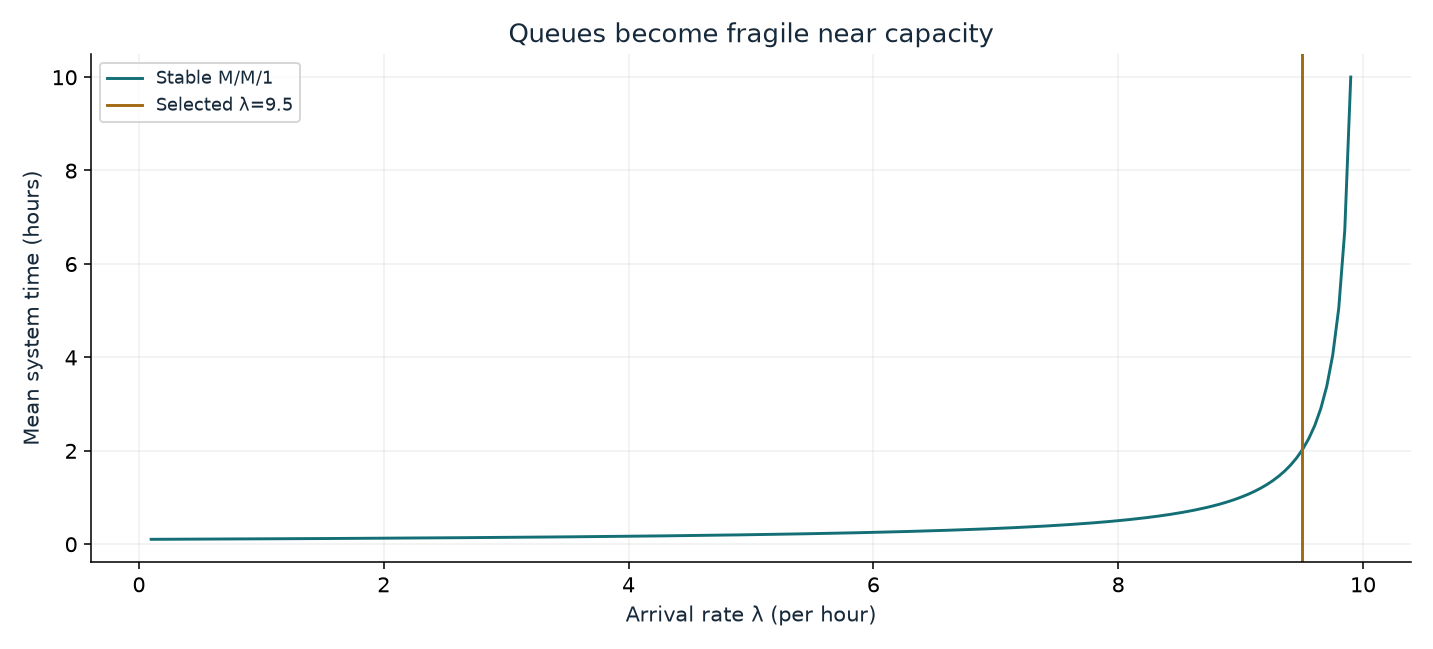

- **Utilization:** 0.95
- **Mean system time:** 2.0
- **Mean customers in system:** 19.0

At service rate 10/hour and arrivals 9.5/hour, mean system time is 2 hours under the M/M/1 assumptions.

In [2]:
figure, metrics, interpretation=illustrate(14,1,9.5)
buffer=io.BytesIO()
figure.savefig(buffer,format='png',dpi=140,bbox_inches='tight',pad_inches=.16)
display(Image(data=buffer.getvalue(),alt='Approach the queue capacity boundary'))
plt.close(figure)
display(Markdown('\n'.join('- **'+str(k)+':** '+str(v) for k,v in metrics.items())))
display(Markdown(interpretation))


**Use the idea:** Use rule 14.3.3 when its stated conditions fit. Compare the calculation with your own decision threshold; retain the relevant error or uncertainty.

**Assumptions and limits:** Stationary M/M/1 queue, exponential service, Poisson arrivals, μ=10/hour.

<details><summary>Can you report a negative wait when λ exceeds μ?</summary>

No. The stationary formula is invalid at or above capacity; a negative output would be a model-use error.

</details>

**Book source:** [Rule 14.3.3: M/M/1 Delay Blows Up Near Capacity](source.html).

## C14-D02: Follow a correlated shock through time

Does a higher φ make the same shock vanish sooner?

Plot the decay of one shock and compare its half-life with long-run variance amplification.

$$
\phi^h=\frac12,\quad h=\frac{\log(.5)}{\log\phi}
$$

**Symbols and inputs:** AR(1) coefficient φ. Stationary AR(1), 0<φ<1, independent innovation model for the variance factor.

**Predict:** Does a higher φ make the same shock vanish sooner?

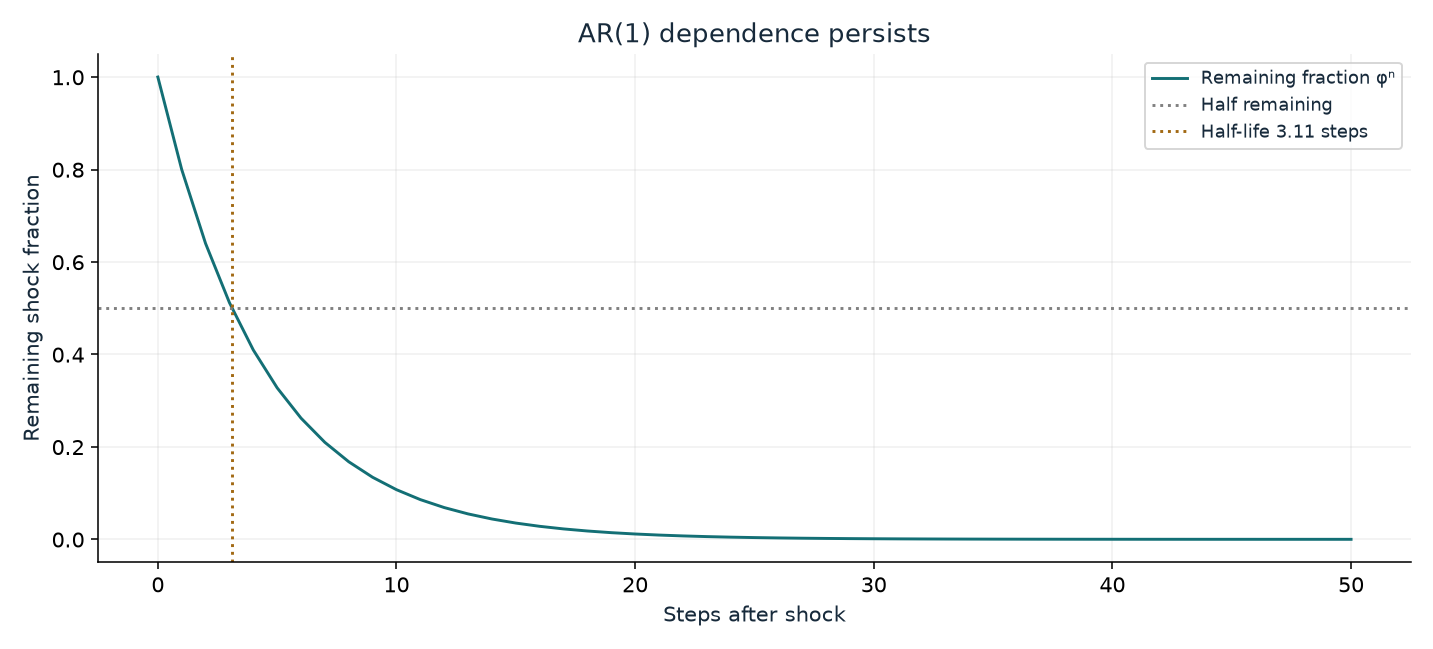

- **AR coefficient:** 0.8
- **Half-life in steps:** 3.1062837195053903
- **Long-run variance factor:** 9.000000000000002

A shock is multiplied by φ=0.8 each step (it keeps 80% per step), with half-life 3.11 steps. A long average is 9 times as noisy (in variance) as an average of the same number of independent readings. Lingering shocks make neighboring readings repeat each other, so persistence costs precision.

In [3]:
figure, metrics, interpretation=illustrate(14,2,0.8)
buffer=io.BytesIO()
figure.savefig(buffer,format='png',dpi=140,bbox_inches='tight',pad_inches=.16)
display(Image(data=buffer.getvalue(),alt='Follow a correlated shock through time'))
plt.close(figure)
display(Markdown('\n'.join('- **'+str(k)+':** '+str(v) for k,v in metrics.items())))
display(Markdown(interpretation))


**Use the idea:** Use rule 14.2.3 when its stated conditions fit. Compare the calculation with your own decision threshold; retain the relevant error or uncertainty.

**Assumptions and limits:** Stationary AR(1), 0<φ<1, independent innovation model for the variance factor.

<details><summary>Does a higher φ make the same shock vanish sooner?</summary>

No. A higher positive φ retains more of the shock each step and increases its half-life.

</details>

**Book source:** [Rule 14.2.3: AR(1) Shock Half-Life](source.html).

## C14-D03: Turn exposure into a Poisson count

What mean count do you expect over two hours?

The count distribution and probability of any arrival change with rate times exposure.

$$
N(t)\sim\operatorname{Poisson}(\lambda t)
$$

**Symbols and inputs:** Arrival rate per hour λ. Constant Poisson rate over one hour; independent increments.

**Predict:** What mean count do you expect over two hours?

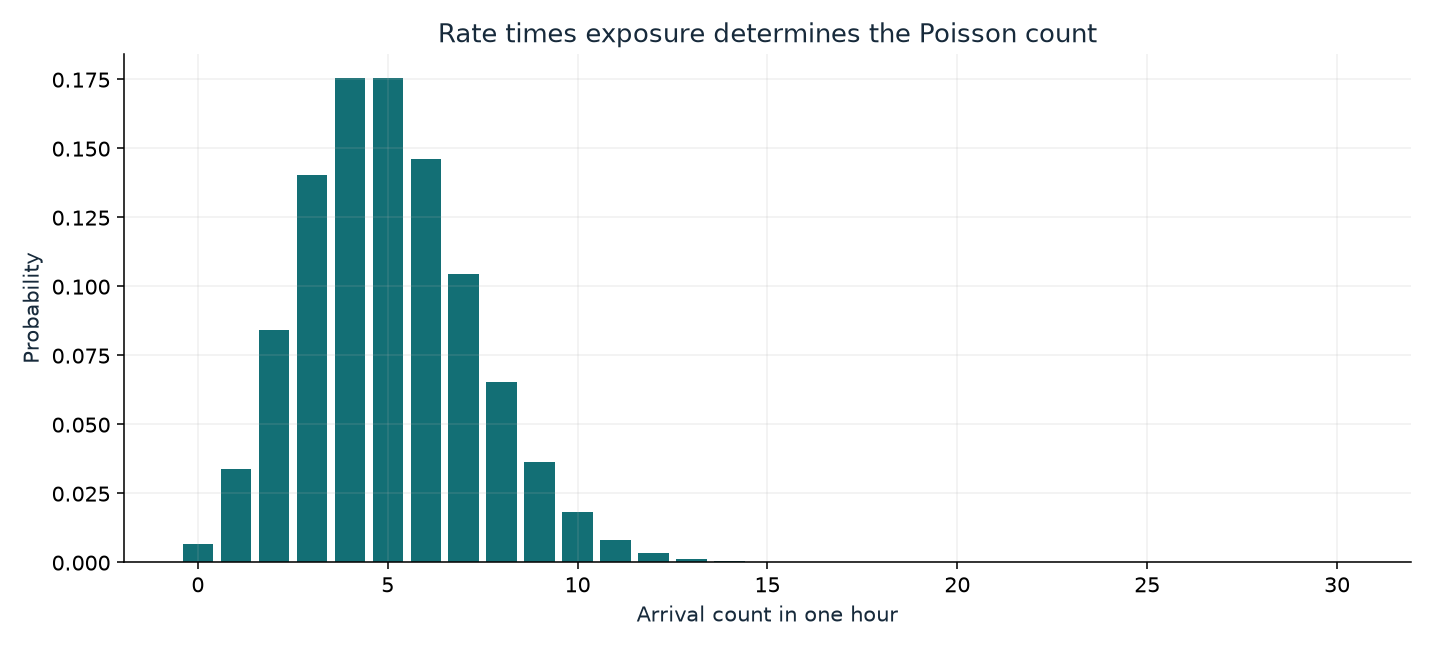

- **Hourly arrival rate:** 5
- **Mean count in one hour:** 5
- **Probability of any arrival:** 0.9932620530009145
- **Mean wait (hours):** 0.2

A constant Poisson rate 5/hour gives mean count 5 in one hour and mean exponential wait 0.2 hours. Changing or dependent arrival rates need a different model.

In [4]:
figure, metrics, interpretation=illustrate(14,3,5)
buffer=io.BytesIO()
figure.savefig(buffer,format='png',dpi=140,bbox_inches='tight',pad_inches=.16)
display(Image(data=buffer.getvalue(),alt='Turn exposure into a Poisson count'))
plt.close(figure)
display(Markdown('\n'.join('- **'+str(k)+':** '+str(v) for k,v in metrics.items())))
display(Markdown(interpretation))


**Use the idea:** Use rule 14.1.1 when its stated conditions fit. Compare the calculation with your own decision threshold; retain the relevant error or uncertainty.

**Assumptions and limits:** Constant Poisson rate over one hour; independent increments.

<details><summary>What mean count do you expect over two hours?</summary>

Twice the hourly rate. The exposure duration must accompany the rate.

</details>

**Book source:** [Rule 14.1.1: Poisson Count Equals Rate Times Exposure](source.html).

## C14-D04: Watch a random walk spread like a square root

If a walker takes 100 times more steps, how much farther does it typically get?

Five sample walks wander around the ±√n curves. The root-mean-square distance of 2000 walks tracks √n.

$$
\sqrt{E[S_n^2]}=\sqrt n
$$

**Symbols and inputs:** Steps n. Fair independent ±1 steps, seed 1421. RMS is a typical distance, not a bound on any one walk.

**Predict:** If a walker takes 100 times more steps, how much farther does it typically get?

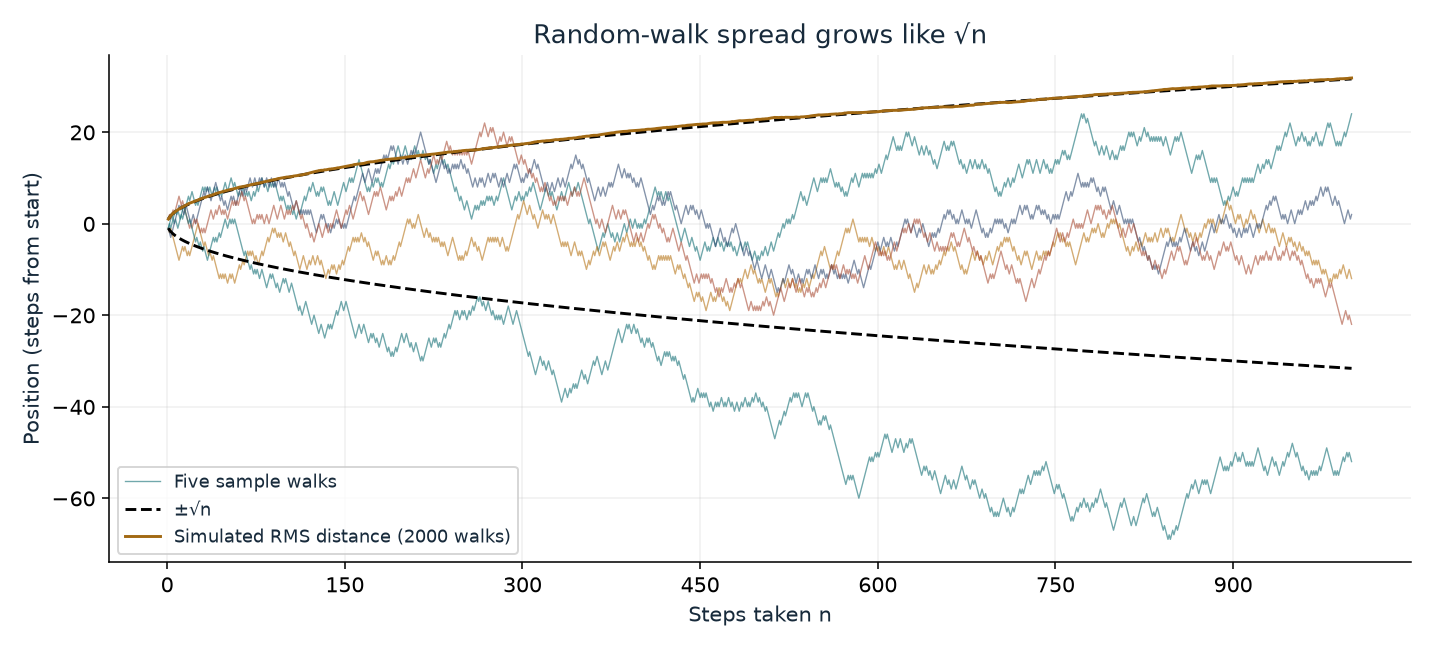

- **Steps:** 1000
- **Theory √n:** 31.622776601683793
- **Simulated RMS distance:** 31.831054019620524
- **Typical distance / steps:** 0.031831054019620525
- **Seed:** 1421

After 1,000 fair ±1 steps, the typical distance from start is about √1,000=31.62 steps (simulation: 31.83). That is only 3.2% of the steps taken. Ten times more steps would move the walker only about 3.16 times farther.

In [5]:
figure, metrics, interpretation=illustrate(14,4,1000)
buffer=io.BytesIO()
figure.savefig(buffer,format='png',dpi=140,bbox_inches='tight',pad_inches=.16)
display(Image(data=buffer.getvalue(),alt='Watch a random walk spread like a square root'))
plt.close(figure)
display(Markdown('\n'.join('- **'+str(k)+':** '+str(v) for k,v in metrics.items())))
display(Markdown(interpretation))


**Use the idea:** Use rule 14.2.1 when its stated conditions fit. Compare the calculation with your own decision threshold; retain the relevant error or uncertainty.

**Assumptions and limits:** Fair independent ±1 steps, seed 1421. RMS is a typical distance, not a bound on any one walk.

<details><summary>If a walker takes 100 times more steps, how much farther does it typically get?</summary>

Ten times farther, since √100=10.

</details>

**Book source:** [Rule 14.2.1: Random-Walk Displacement Grows as Root N](source.html).

## C14-D05: Check whether waiting makes the end nearer

For an exponential wait with mean 10 minutes, after 15 minutes of waiting, what is the expected extra wait?

Compare the remaining-wait curve of a memoryless exponential wait with an aging wait that has the same 10-minute mean.

$$
P(T>s+t\mid T>s)=P(T>t)=e^{-t/\mu}
$$

**Symbols and inputs:** Minutes already waited s. Exponential with mean 10 minutes versus Weibull shape 2 with mean 10 minutes. Constructed models, not observed data.

**Predict:** For an exponential wait with mean 10 minutes, after 15 minutes of waiting, what is the expected extra wait?

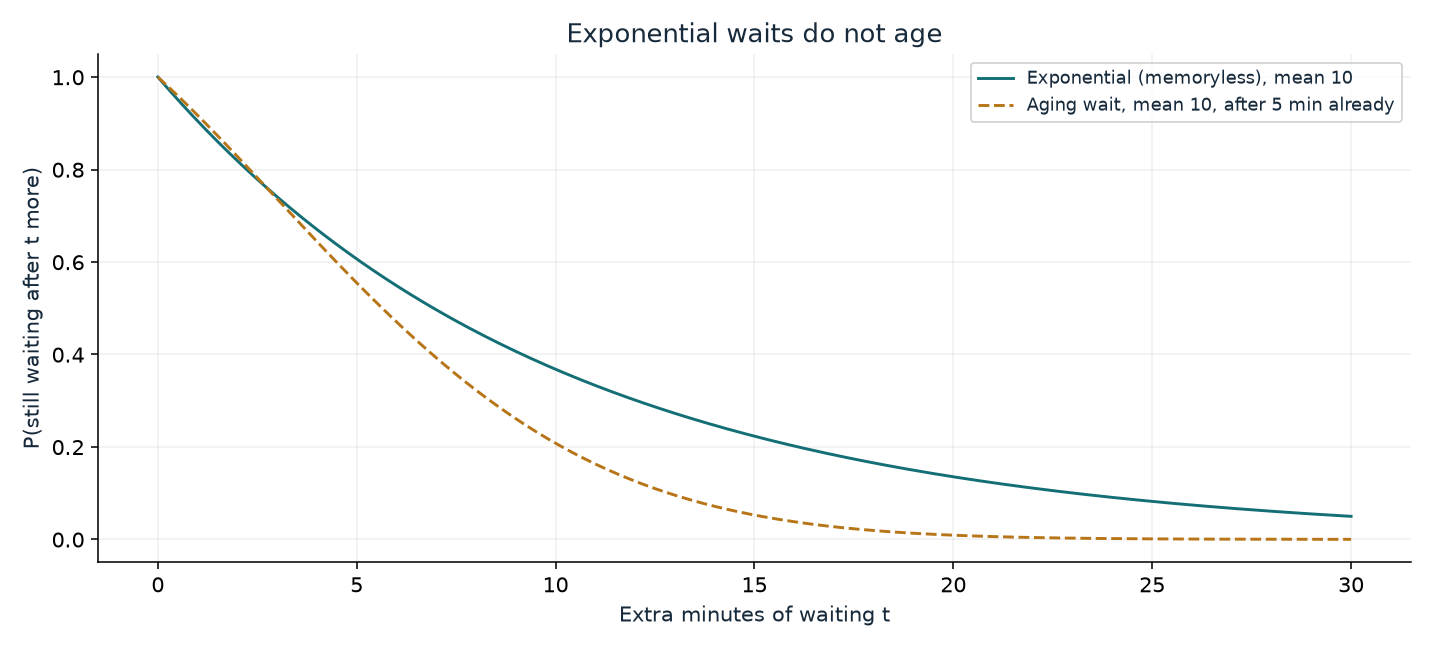

- **Minutes already waited:** 5
- **Exponential: expected extra wait:** 10
- **Aging model: expected extra wait:** 6.460605174728936
- **Exponential: P(over 10 more):** 0.36787944117144233
- **Aging model: P(over 10 more):** 0.20787957635076215

After 5 minutes already waited, a memoryless (exponential) wait still has mean 10 more minutes and a 36.8% chance of lasting 10 more: the past wait is forgotten. An aging wait with the same 10-minute mean (Weibull shape 2) now expects only 6.46 more minutes. Whether waiting longer makes the end nearer depends on the model, not on intuition.

In [6]:
figure, metrics, interpretation=illustrate(14,5,5)
buffer=io.BytesIO()
figure.savefig(buffer,format='png',dpi=140,bbox_inches='tight',pad_inches=.16)
display(Image(data=buffer.getvalue(),alt='Check whether waiting makes the end nearer'))
plt.close(figure)
display(Markdown('\n'.join('- **'+str(k)+':** '+str(v) for k,v in metrics.items())))
display(Markdown(interpretation))


**Use the idea:** Use rule 14.1.4 when its stated conditions fit. Compare the calculation with your own decision threshold; retain the relevant error or uncertainty.

**Assumptions and limits:** Exponential with mean 10 minutes versus Weibull shape 2 with mean 10 minutes. Constructed models, not observed data.

<details><summary>For an exponential wait with mean 10 minutes, after 15 minutes of waiting, what is the expected extra wait?</summary>

Still 10 minutes. The exponential forgets the past; only an aging model shortens the remaining wait.

</details>

**Book source:** [Rule 14.1.4: Memorylessness Means No Aging](source.html).

## Exercises and solutions

A decision worksheet, an additional calculation, exercises and solutions follow.

# Chapter 14 notebook: Stochastic Processes: Rates, Waiting, and Dependence

**Goal:** Recognize when a steady-state queue estimate exists and why delay rises near capacity.

**Start with:** Rules 14.3.1, 14.3.2, 14.3.3. Use a calculator or the optional Python lab. All lab numbers are constructed practice inputs, not observed data.

**Source:** [Finished Chapter 14](source.html) from *Mathematical Rules of Thumb*. Numbered rules, classifications, and the decision path come from the book. The lab, exercises, answer key, and worksheet prompts are companion additions.

## 1. Frame your decision

Write a question in which an answer would change something you do. Gather: Rate and time units; arrival/service model; stationarity; dependence; system boundary; whether count, wait, inventory, or mixing is sought.

- My question and intended decision:
- Known inputs and units:
- Required accuracy or threshold:
- What I expect before calculating:
- What I still need to find out:

Use the lab as a worked starting point if you do not yet have your own problem.

## 2. Choose a route

- **Do you have a stable event rate and an exposure?** Use $\lambda t$ for a Poisson count scale. Use the zero-count complement for event risk and $1/\lambda$ for an exponential mean wait.
- **Are event streams being combined or split?** Add rates only for independent Poisson streams. Multiply by label probabilities only for eventwise-independent thinning.
- **Is the total count fixed?** Simulate homogeneous event locations as sorted uniforms; otherwise retain the exponential-gap view.
- **Is randomness accumulating through independent centered increments?** Expect root-time or root-step spread. Add drift separately and inspect dependence.
- **Is a time series persistent?** Translate $\phi$ into half-life and stationary variance only after checking $|\phi|<1$ and the adequacy of an AR(1) model.
- **Is a smoother or renewal process being summarized?** Convert EWMA weight to a variance-equivalent window, or wait moments to a long-horizon count approximation, while keeping their regimes explicit.
- **Is a Markov chain being run?** Estimate its slowest dependence scale, then use multiple-chain evidence and estimand-specific ESS rather than nominal iterations.
- **Is a queue or flow system involved?** Apply Little's law with consistent boundaries. For M/M/1 calculations, establish $\rho<1$ before evaluating delay and preserve capacity headroom.
- **Is $0.234$ proposed as a tuning target?** Confirm high-dimensional random-walk Metropolis assumptions; otherwise use diagnostics appropriate to the actual sampler.

**Chapter-specific stop check:** Little's law uses compatible system boundaries and long-run averages; M/M/1 delay adds specific queue assumptions. Nominal simulation draws are not automatically independent draws.

## 3. Work the lab

An M/M/1 station has arrival rate 8 per hour and service rate 10 per hour. Utilization is 0.8. Mean total time in the system is W=1/(10-8)=0.5 hours; Little's law gives L=8 × 0.5=4 jobs. At 9 arrivals per hour W doubles to 1 hour. At arrival rate equal to service rate the stationary formula is invalid, rather than a usable finite prediction.

Predict the sign and scale before running the code. Then change one input and explain why the result moves. The code checks the constructed example; it does not prove the rule for every possible input. Code assertions may describe the example's chosen regime, so inspect them before changing that regime.

In [7]:
service_rate = 10.0
for arrival_rate in (8.0, 9.0, 9.5):
    assert 0 <= arrival_rate < service_rate
    utilization = arrival_rate/service_rate
    time_hours = 1/(service_rate-arrival_rate)
    inventory = arrival_rate*time_hours
    print(f"Arrivals/h={arrival_rate:.1f}; utilization={utilization:.2f}; total time={time_hours:.2f} h; inventory={inventory:.2f}")

Arrivals/h=8.0; utilization=0.80; total time=0.50 h; inventory=4.00
Arrivals/h=9.0; utilization=0.90; total time=1.00 h; inventory=9.00
Arrivals/h=9.5; utilization=0.95; total time=2.00 h; inventory=19.00


**My prediction, observed result, and explanation:**

_Record your work here._

## 4. Practise without the answers

### Exercise 1

A homogeneous Poisson process averages two arrivals per hour. Find the chance of at least one in 15 minutes.

**My approach, assumptions, calculation, and check:**

_Write your attempt here._

### Exercise 2

A positive stationary AR(1) coefficient is 0.8. Estimate shock half-life in observation periods.

**My approach, assumptions, calculation, and check:**

_Write your attempt here._

### Exercise 3

Can you insert arrivals 12/h and service 10/h into W=1/(mu-lambda) and interpret the negative result?

**My approach, assumptions, calculation, and check:**

_Write your attempt here._

**Tip:** Attempt Exercise 2 before reading the answer key, and check the assumptions before you check the number.

## 5. Answer key and reasoning

Read this after attempting the exercises, or use it immediately if you prefer a complete walkthrough. An answer is complete only when its assumptions and stopping point are clear.

### Answer 1

Exposure is 0.25 hours; lambda × t=0.5. Probability is 1-exp(-0.5)≈0.393469.

### Answer 2

log(0.5)/log(0.8)≈3.1063 periods. This describes the geometric decay of the model's expected shock response.

### Answer 3

No. Utilization exceeds one and this M/M/1 system has no stationary finite mean delay. Change capacity, demand, or the model before using a steady-state formula.

## 6. Build the complete chapter toolkit

The new lab samples the chapter; the following checklist covers all 20 rules. Study one thematic group at a time. A large group can take several sessions.

- **Poisson Arrivals and Exponential Waiting:** work with rules 14.1.1, 14.1.2, 14.1.3, 14.1.4, 14.1.5, 14.1.6, 14.1.7.
- **Scaling and Memory Across Time:** work with rules 14.2.1, 14.2.2, 14.2.3, 14.2.4, 14.2.5, 14.2.6, 14.2.7.
- **Flow Systems and Simulation Guardrails:** work with rules 14.3.1, 14.3.2, 14.3.3, 14.3.4, 14.3.5, 14.3.6.

For each selected rule, read its equation, explanation, and worked use in the source. Reproduce that example; change one input; then change one assumption so the rule is no longer justified. Record the result and what check catches the failure. Historical examples remain labeled and qualified as in the source.

Read each complete numbered profile in the [chapter reference](source.html) before applying it. The cues below are abbreviated; they are not complete conditions. Change the status only after doing the practice described below.

| Rule | Book role | First assumptions to inspect | Practice status |
|---|---|---|---|
| 14.1.1: Poisson Count Equals Rate Times Exposure | Independent | homogeneous poisson process;  known rate and exposure | new |
| 14.1.2: At Least One Poisson Arrival | Independent | homogeneous poisson process;  known rate and exposure | new |
| 14.1.3: Mean Exponential Wait Is the Inverse Rate | Independent | homogeneous poisson arrivals;  positive constant rate | new |
| 14.1.4: Memorylessness Means No Aging | Independent | nonnegative waiting time;  exact memoryless property | new |
| 14.1.5: Superposed Poisson Rates Add | Independent | independent poisson streams;  compatible time units | new |
| 14.1.6: Poisson Thinning Multiplies the Rate | Independent | poisson input stream;  independent constant retention | new |
| 14.1.7: Poisson Arrival Times Are Uniform Given the Count | Independent | homogeneous poisson process;  fixed interval | new |
| 14.2.1: Random-Walk Displacement Grows as Root N | Independent | independent zero mean steps;  finite step variance | new |
| 14.2.2: Diffusion Distance from \(2Dt\) | Independent | one dimensional brownian diffusion;  constant diffusivity | new |
| 14.2.3: AR(1) Shock Half-Life | Independent | positive ar1 coefficient below one;  stable coefficient | new |
| 14.2.4: AR(1) Long-Run Variance Amplification | Independent | stationary ar1 process;  independent finite variance innovations | new |
| 14.2.5: EWMA Effective Window Length | Independent | constant smoothing factor;  long series | new |
| 14.2.6: Renewal Count Mean and Variance at Long Times | Independent | iid positive interarrivals;  finite mean and variance | new |
| 14.2.7: Markov Mixing Scale from the Second Eigenvalue | Independent | finite reversible ergodic chain;  known nonstationary eigenvalue | new |
| 14.3.1: Little's Law: Inventory Equals Throughput Times Time | Independent | stable flow system;  consistent customer boundary | new |
| 14.3.2: M/M/1 Stability Requires Utilization Below One | Workflow | m m 1 queue;  steady state objective | new |
| 14.3.3: M/M/1 Delay Blows Up Near Capacity | Independent | poisson arrivals;  exponential service | new |
| 14.3.4: MCMC Effective Sample Size from Autocorrelation | Workflow | stationary ergodic chain;  reliable autocorrelation estimate | new |
| 14.3.5: Burn In for Several Dependence Time Scales | Workflow | ergodic markov chain;  estimated relaxation time | new |
| 14.3.6: The 0.234 Random-Walk Metropolis Benchmark | Workflow | high dimension;  smooth product like target | new |

For a completed row, record: **rule number / my new input / mathematical claim type / verified assumptions / calculation / check / valid use / rejected use / next step**. “Practised” means you worked an example. “Demonstrated” means you can explain a valid use, transfer it, and reject a misuse without the answer key.

## 7. Apply it to your own problem

Return to your opening question. Choose the smallest rule set that can settle it. Use the book's independent/workflow/specialized classification separately from the claim type (exact, approximate, bound, diagnostic, or heuristic).

- Selected rule number(s) and reason:
- Assumptions that hold, fail, or remain uncertain:
- Substitution with units:
- Result and error, uncertainty, or bound:
- Independent check or limiting case:
- Decision this supports:
- Stop here, do a named next calculation, or gather missing information:

## 8. Transfer and continue

Useful nearby chapters: Chapter 12: probability; Chapter 13: statistics; Chapter 19: optimization. Bring the question, units, assumptions, result type, and uncertainty to the next chapter. Choose a bridge only when it supplies an operation you actually need.

**Completion check:** Explain this chapter's lab in your own words; solve one changed-input exercise; reject one invalid use; and produce a decision record for your own problem. If one check fails, revisit that part of the chapter rather than marking every rule complete.